# Proyecto 2 — Fine-tuning para tareas de NLP

**Fundamentos de Procesamiento de Lenguaje Natural** · Ingeniería de Sistemas · Universidad de Antioquia
Prof. Antonio Jesús Tamayo Herrera, Ph.D.

**Realizado por:** _Quelix Xiomara Pérez_  ·  **Usuario Hugging Face:** _xiomara0327_

Este notebook aplica **fine-tuning** a modelos preentrenados para tres tipos de problema de NLP:

| # | Tipo de problema | Dataset (Hugging Face) | Modelo base | Métrica principal |
|---|---|---|---|---|
| 1 | Clasificación de secuencias | `nyu-mll/glue` (SST-2) | DistilBERT (encoder) | Accuracy / F1 |
| 2 | Etiquetado de secuencias (NER) | `lhoestq/conll2003` | DistilBERT (encoder) | F1 a nivel de entidad (seqeval) |
| 3 | Secuencia a secuencia (resumen) | `knkarthick/samsum` | T5-small (encoder-decoder) | ROUGE-1/2/L |

**Metodología común a las tres tareas**
1. Describir y explorar el dataset.
2. Tokenizar con el tokenizador del modelo.
3. Calcular un baseline simple: si el modelo no lo supera, el fine-tuning no aporta.
4. Búsqueda de hiperparámetros sobre una *muestra manejable* (pocos datos, pocas épocas). Se evalúa en un conjunto de validación (*dev*).
5. Entrenar con la mejor configuración sobre todos los datos.
6. Evaluar una sola vez en el conjunto de prueba reservado y analizar los errores.

## 0. Preparación del entorno

In [21]:
%pip -q install -U transformers datasets evaluate accelerate huggingface_hub
%pip -q install seqeval rouge_score sentencepiece

In [22]:
DEBUG = False
USE_DRIVE = True
PUSH_TO_HUB = True

In [23]:
import os, gc, json, time, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import transformers, datasets, evaluate
from packaging import version
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, AutoModelForTokenClassification,
    AutoModelForSeq2SeqLM, DataCollatorWithPadding, DataCollatorForTokenClassification,
    DataCollatorForSeq2Seq, TrainingArguments, Trainer, EarlyStoppingCallback,
    Seq2SeqTrainingArguments, Seq2SeqTrainer, pipeline, set_seed,
)
from transformers.trainer_utils import get_last_checkpoint

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); set_seed(SEED)

HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda" if HAS_GPU else "cpu"

# Carpeta de salida (Drive si está disponible). En DEBUG se usa otra carpeta para no mezclar resultados.
BASE = "outputs"
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = "/content/drive/MyDrive/proyecto2_nlp"
    except Exception as e:
        print("Drive no disponible, se usa disco local:", e)
OUT = BASE + ("_debug" if DEBUG else "")
os.makedirs(OUT, exist_ok=True)

# Compatibilidad: el argumento del tokenizador en Trainer cambió de nombre (v4.46+)
TOK_KW = "processing_class" if version.parse(transformers.__version__) >= version.parse("4.46.0") else "tokenizer"

print("Transformers:", transformers.__version__, "| Datasets:", datasets.__version__, "| PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "NO HAY GPU (el entrenamiento será muy lento)")
print("Carpeta de salida:", OUT)

Drive no disponible, se usa disco local: Error: credential propagation was unsuccessful
Transformers: 5.24.0 | Datasets: 5.2.0 | PyTorch: 2.14.1+cu130
GPU: Tesla T4
Carpeta de salida: outputs


### 0.1 Cuenta de Hugging Face
Se guarda como *secreto* el token de Hugging Face con el nombre de `HF_TOKEN`

In [24]:
from huggingface_hub import login, notebook_login, HfApi
try:
    from google.colab import userdata
    login(token=userdata.get("HF_TOKEN"))
except Exception:
    notebook_login()

PUSH_TO_HUB = PUSH_TO_HUB and not DEBUG
try:
    HF_USER = HfApi().whoami()["name"]
    print("Sesión iniciada como:", HF_USER)
except Exception as e:
    HF_USER, PUSH_TO_HUB = None, False
    print("No se pudo verificar la sesión; PUSH_TO_HUB desactivado.", e)

No se pudo verificar la sesión; PUSH_TO_HUB desactivado. Invalid user token. The token from Google Colab vault is invalid. Please update it from the UI.


In [25]:
CFG = {
    "sst2": dict(model="distilbert-base-uncased", n_trials=8, confirm_top=2,
                 search_train=5000, search_eval=None, search_epochs=2,
                 final_epochs=3, max_final_train=None, max_len=128),
    "ner":  dict(model="distilbert-base-cased",
                 n_trials=8, confirm_top=2,
                 search_train=3000, search_eval=1000, search_epochs=2,
                 final_epochs=4, max_final_train=None, max_len=256),
    "sum":  dict(model="t5-small",
                 n_trials=6, confirm_top=2,
                 search_train=3000, search_eval=500, search_epochs=3,
                 final_epochs=6, max_final_train=None,
                 max_input=512, max_target=64),
}

# Valores posibles de cada hiperparámetro (lr = learning rate, bs = batch size, warmup = proporción de pasos de calentamiento)
SPACE = {
    "sst2": dict(lr=[1e-5, 2e-5, 3e-5, 5e-5, 1e-4], bs=[16, 32, 64], weight_decay=[0.0, 0.01, 0.1],
                 warmup=[0.0, 0.06, 0.1], scheduler=["linear", "cosine"], label_smoothing=[0.0, 0.1]),
    "ner":  dict(lr=[1e-5, 3e-5, 5e-5, 1e-4], bs=[8, 16, 32], weight_decay=[0.0, 0.01, 0.1],
                 warmup=[0.0, 0.06, 0.1], scheduler=["linear", "cosine"]),
    "sum":  dict(lr=[1e-4, 3e-4, 5e-4, 1e-3], bs=[8, 16, 32], weight_decay=[0.0, 0.01, 0.1],
                 warmup=[0.0, 0.06, 0.1], scheduler=["linear", "cosine"], label_smoothing=[0.0, 0.1]),
}
# Configuración "de manual" que siempre se evalúa como primer intento
DEFAULTS = {
    "sst2": dict(lr=3e-5, bs=32, weight_decay=0.01, warmup=0.1, scheduler="linear", label_smoothing=0.0),
    "ner":  dict(lr=5e-5, bs=16, weight_decay=0.01, warmup=0.1, scheduler="linear"),
    "sum":  dict(lr=3e-4, bs=16, weight_decay=0.01, warmup=0.1, scheduler="linear", label_smoothing=0.0),
}

if DEBUG:
    for c in CFG.values():
        c.update(n_trials=3, confirm_top=0, search_train=200, search_eval=100, search_epochs=1,
                 final_epochs=1, max_final_train=300)

# T4 no soporta bf16 y T5 es inestable en fp16 -> fp16 solo para los encoders
USE_FP16 = HAS_GPU
print(json.dumps(CFG, indent=1))

{
 "sst2": {
  "model": "distilbert-base-uncased",
  "n_trials": 8,
  "confirm_top": 2,
  "search_train": 5000,
  "search_eval": null,
  "search_epochs": 2,
  "final_epochs": 3,
  "max_final_train": null,
  "max_len": 128
 },
 "ner": {
  "model": "distilbert-base-cased",
  "n_trials": 8,
  "confirm_top": 2,
  "search_train": 3000,
  "search_eval": 1000,
  "search_epochs": 2,
  "final_epochs": 4,
  "max_final_train": null,
  "max_len": 256
 },
 "sum": {
  "model": "t5-small",
  "n_trials": 6,
  "confirm_top": 2,
  "search_train": 3000,
  "search_eval": 500,
  "search_epochs": 3,
  "final_epochs": 6,
  "max_final_train": null,
  "max_input": 512,
  "max_target": 64
 }
}


### 0.2 Utilidades compartidas

In [26]:
def subsample(ds, n, seed=SEED):
    # muestra reproducible de n ejemplos (o el dataset completo si n es None / mayor)
    if n is None or n >= len(ds):
        return ds
    return ds.shuffle(seed=seed).select(range(n))

def free_memory():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

def split_overview(ds_dict):
    return pd.DataFrame([{"partición": k, "ejemplos": len(v), "columnas": ", ".join(v.column_names)}
                         for k, v in ds_dict.items()])

def length_report(lengths, max_len, name):
    # estadísticas de longitud en tokens y % de ejemplos que se truncarían con max_len
    a = np.asarray(lengths)
    print(f"{name}: mediana={np.median(a):.0f} | p95={np.percentile(a, 95):.0f} | p99={np.percentile(a, 99):.0f} "
          f"| máx={a.max()} | truncados con max_len={max_len}: {100 * (a > max_len).mean():.2f}%")

def warmup_kw(r):
    # en versiones nuevas warmup_ratio pasó a warmup_steps (un float < 1 se interpreta como proporción)
    return {"warmup_ratio": r} if "warmup_ratio" in TrainingArguments.__dataclass_fields__ else {"warmup_steps": r}

def make_args(cls, output_dir, hp, epochs, final, metric, fp16, seed=SEED, **extra):
    # hp = dict con lr, bs, weight_decay, warmup, scheduler y (opcional) label_smoothing.
    # En búsqueda: sin checkpoints, se evalúa una vez al final.
    # En entrenamiento final: evalúa y guarda cada época y se queda con la mejor.
    kw = dict(
        output_dir=output_dir, learning_rate=hp["lr"], num_train_epochs=epochs,
        per_device_train_batch_size=int(hp["bs"]), per_device_eval_batch_size=min(int(hp["bs"]) * 2, 64),
        weight_decay=hp["weight_decay"], lr_scheduler_type=hp["scheduler"],
        label_smoothing_factor=hp.get("label_smoothing", 0.0),
        logging_steps=100, report_to="none", seed=seed, fp16=fp16,
        eval_strategy="epoch" if final else "no",
        save_strategy="epoch" if final else "no",
        load_best_model_at_end=final,
        metric_for_best_model=metric if final else None,
        greater_is_better=True, save_total_limit=1,
    )
    kw.update(warmup_kw(hp["warmup"]))
    kw.update(extra)
    return cls(**kw)

def hp_tag(trial, hp):
    # identifica el entrenamiento final por configuración: un checkpoint viejo con otros hiperparámetros no se reanuda por error
    return f"t{trial}_" + hashlib.md5(json.dumps(hp, sort_keys=True, default=str).encode()).hexdigest()[:6]

def callbacks_for(final, epochs):
    # early stopping solo en el entrenamiento final y si hay suficientes épocas
    return [EarlyStoppingCallback(early_stopping_patience=2)] if final and epochs > 2 else None

def fit(trainer, out_dir):
    # entrena reanudando desde el último checkpoint si la sesión de Colab se cayó
    ck = get_last_checkpoint(out_dir) if os.path.isdir(out_dir) else None
    if ck: print("Reanudando desde", ck)
    return trainer.train(resume_from_checkpoint=ck)

# ---------------------------- búsqueda de hiperparámetros ----------------------------
_DROP = {"runtime", "samples_per_second", "steps_per_second", "epoch"}
_META = {"trial", "seed", "train_loss", "minutos"}

def sample_trials(space, defaults, n, seed=SEED):
    # configuración por defecto + (n-1) configuraciones sorteadas sin repetir (random search)
    rng = random.Random(seed)
    trials, seen = [dict(defaults)], {tuple(sorted(defaults.items()))}
    for _ in range(10000):
        if len(trials) >= n: break
        t = {k: rng.choice(v) for k, v in space.items()}
        key = tuple(sorted(t.items()))
        if key not in seen:
            seen.add(key); trials.append(t)
    return trials[:n]

def run_hp_search(task, build_fn, train_ds, eval_ds, space, defaults, n_trials, epochs, main, confirm_top=2, confirm_seed=7):
    # Etapa 1: cada configuración con la semilla base. Etapa 2: las mejores `confirm_top` se repiten con otra semilla.
    # Cada corrida se guarda en CSV; si la sesión se cae, al repetir la celda se saltan las ya hechas.
    trials = sample_trials(space, defaults, n_trials)
    raw_path = f"{OUT}/{task}_hp_raw.csv"
    rows = pd.read_csv(raw_path).to_dict("records") if os.path.exists(raw_path) else []
    done = {(int(r["trial"]), int(r["seed"])) for r in rows}
    if rows: print(f"Reanudando búsqueda: {len(done)} corridas ya hechas")

    def run(tid, seed):
        if (tid, seed) in done: return
        hp = trials[tid]; set_seed(seed); t0 = time.time()
        row = {"trial": tid, **hp, "seed": seed}
        try:
            tr = build_fn(hp, train_ds, eval_ds, epochs, f"{OUT}/{task}_search_t{tid}_s{seed}", final=False, seed=seed)
            res = tr.train(); ev = tr.evaluate()
            row.update(train_loss=res.training_loss, minutos=(time.time() - t0) / 60)
            row.update({k[5:]: v for k, v in ev.items()
                        if k.startswith("eval_") and k[5:] not in _DROP and isinstance(v, (int, float))})
            del tr
        except RuntimeError as e:                      # p. ej. batch size demasiado grande para la GPU
            if "out of memory" not in str(e).lower(): raise
            print(f"  configuración {tid}: sin memoria con bs={hp['bs']}, se descarta")
            row.update(train_loss=np.nan, minutos=(time.time() - t0) / 60, **{main: np.nan})
        free_memory()
        rows.append(row); done.add((tid, seed))
        pd.DataFrame(rows).to_csv(raw_path, index=False)
        print({k: (round(float(v), 4) if isinstance(v, (float, np.floating)) and k != "lr" else v) for k, v in row.items()})

    for tid in range(len(trials)):
        run(tid, SEED)
    s1 = pd.DataFrame(rows)
    s1 = s1[s1["seed"] == SEED].dropna(subset=[main])
    for tid in s1.sort_values(main, ascending=False)["trial"].head(confirm_top).astype(int):
        run(tid, confirm_seed)

    raw = pd.DataFrame(rows)
    keys = list(space)
    metric_cols = [c for c in raw.columns if c not in set(keys) | _META]
    g = raw.groupby("trial")
    agg = {k: "first" for k in keys}; agg.update({c: "mean" for c in metric_cols}); agg.update(train_loss="mean", minutos="sum")
    summ = g.agg(agg)
    summ[f"{main}_std"] = g[main].std(ddof=0)
    summ["n_semillas"] = g[main].count()
    summ = summ.reset_index().sort_values(main, ascending=False, na_position="last").reset_index(drop=True)
    _num = [c for c in summ.columns if c not in set(keys) | {"trial"}]
    summ[_num] = summ[_num].round(4)       # se redondean solo las métricas: redondear 'lr' (p. ej. 1e-5) lo dejaría en 0.0
    summ.to_csv(f"{OUT}/{task}_hp.csv", index=False)
    return summ, raw

def pick_best_hp(summ, space, main):
    cols = ["trial"] + list(space) + [main, f"{main}_std", "n_semillas"]
    print("Top 5 configuraciones (media sobre las semillas disponibles):")
    display(summ[cols].head(5))
    row = summ.iloc[0]
    hp = {k: (row[k].item() if hasattr(row[k], "item") else row[k]) for k in space}
    print("Mejor configuración:", hp, f"-> {main} = {row[main]}")
    if len(summ) > 1 and summ[main].iloc[0] - summ[main].iloc[1] < summ[f"{main}_std"].iloc[:2].max():
        print("Ojo: las dos mejores están a menos de 1 desviación entre semillas; la diferencia puede ser ruido.")
    return hp, int(row["trial"])

def plot_hp_effects(raw, space, main, title=""):
    # efecto marginal de cada hiperparámetro: media del dev entre todas las corridas que usaron ese valor.
    # Es orientativo (pocas configuraciones, varios hiperparámetros cambian a la vez); las barras son la dispersión.
    keys = [k for k in space if raw[k].nunique() > 1]
    fig, axes = plt.subplots(1, len(keys), figsize=(3.2 * len(keys), 3.4), squeeze=False)
    for ax, k in zip(axes[0], keys):
        g = raw.groupby(k)[main].agg(["mean", "std"]).reset_index()
        ax.errorbar(range(len(g)), g["mean"], yerr=g["std"].fillna(0), marker="o", capsize=3)
        ax.set_xticks(range(len(g))); ax.set_xticklabels([str(x) for x in g[k]], rotation=45)
        ax.set_title(k); ax.grid(alpha=.3)
    axes[0][0].set_ylabel(main); plt.suptitle(f"{title}: efecto de cada hiperparámetro en {main} (dev)"); plt.tight_layout(); plt.show()

def plot_trials(summ, main, title, ax):
    ax.bar(range(len(summ)), summ[main], yerr=summ[f"{main}_std"].fillna(0), capsize=3)
    ax.set_xticks(range(len(summ))); ax.set_xticklabels([f"#{t}" for t in summ["trial"]])
    ax.set_title(title); ax.set_xlabel("configuración (ordenadas de mejor a peor)"); ax.grid(alpha=.3, axis="y")

def plot_history(trainer, metric, title):
    # curvas de pérdida de entrenamiento / validación y métrica por época
    logs = trainer.state.log_history
    tr = [(l["step"], l["loss"]) for l in logs if "loss" in l]
    ev = [l for l in logs if "eval_loss" in l]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    if tr: ax[0].plot(*zip(*tr), label="train loss", alpha=.8)
    if ev: ax[0].plot([l["step"] for l in ev], [l["eval_loss"] for l in ev], "o-", label="dev loss")
    ax[0].set_xlabel("paso"); ax[0].set_title(title + ": pérdida"); ax[0].legend(); ax[0].grid(alpha=.3)
    if ev and f"eval_{metric}" in ev[0]:
        ax[1].plot([l["epoch"] for l in ev], [l[f"eval_{metric}"] for l in ev], "o-")
    ax[1].set_xlabel("época"); ax[1].set_title(f"{title}: {metric} en dev"); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

RESULTS = {}   # aquí se acumulan los resultados finales de las 3 tareas

## 1. Clasificación de secuencias — SST-2 (análisis de sentimiento)

**Dataset:** `nyu-mll/glue`, configuración `sst2` (Stanford Sentiment Treebank, binario).

|Aspecto|Descripción |
|---|---|
| **Dominio** | Reseñas de películas |
| **Utilidad** | Detectar automáticamente si una opinión es positiva o negativa (monitoreo de reputación, análisis de reseñas, soporte al cliente) |
| **Entrada** | `sentence`: texto de una oración o fragmento |
| **Salida** | `label`: 0 = negativo, 1 = positivo |
| **Tipo de problema** | Clasificación de secuencias: una etiqueta por secuencia completa |
| **Modelo** | `distilbert-base-uncased` + cabeza de clasificación (2 clases) |
| **Métrica** | Accuracy y F1 |

**Particiones:**
- `train` completo → entrenamiento.
- `validation` oficial (oraciones completas, distintas a las del train) → se divide **50/50 estratificado**: una mitad es **dev** (elegir hiperparámetros y mejor época) y la otra es **prueba final**, usada una sola vez.

In [27]:
sst2 = load_dataset("nyu-mll/glue", "sst2")
print(sst2)
print("\nCaracterísticas:", sst2["train"].features)
sst_labels = sst2["train"].features["label"].names
print("Clases:", sst_labels)
display(split_overview(sst2))

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})

Características: {'sentence': Value('string'), 'label': ClassLabel(names=['negative', 'positive']), 'idx': Value('int32')}
Clases: ['negative', 'positive']


,partición,ejemplos,columnas
0,train,67349,"sentence, label, idx"
1,validation,872,"sentence, label, idx"
2,test,1821,"sentence, label, idx"


### 1.1 Análisis exploratorio

--- NEGATIVE ---
  • a dull , dumb and derivative horror
  • if george romero had directed this movie , it would n't have taken the protagonists a full hour to determine that in order to kill a zombie you must shoot it in the head
  • the acting is amateurish , the cinematography is atrocious
  • maudlin ending
--- POSITIVE ---
  • acted meditation on both the profoundly devastating events of one year ago and the slow , painful healing process that has followed in their wake
  • this odd , poetic road movie , spiked by jolts of pop music , pretty much takes place in morton 's ever-watchful gaze -- and it 's a tribute to the actress , and to her inventive director , that the journey is such a mesmerizing one .
  • directed with purpose and finesse by england 's roger mitchell , who handily makes the move from pleasing , relatively lightweight commercial fare such as notting hill to commercial fare with real thematic heft .
  • long and eventful


,partición,clase,cantidad,%
0,train,negative,29780,44.2
1,train,positive,37569,55.8
2,validation,negative,428,49.1
3,validation,positive,444,50.9


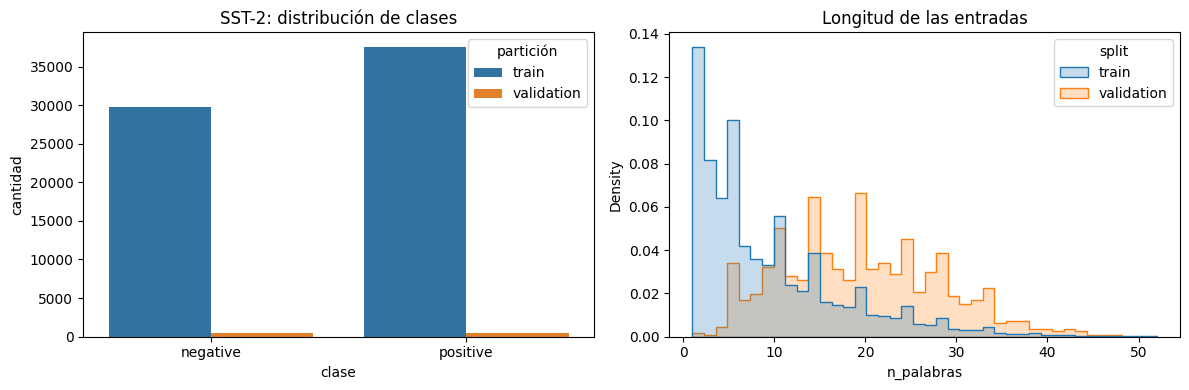

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,67349.0,9.41,8.07,1.0,3.0,7.0,13.0,52.0
validation,872.0,19.55,8.76,2.0,13.0,19.0,26.0,47.0



• Balance: 55.8% de las frases de train son positivas -> accuracy es una métrica razonable.
• Longitud media: train=9.4 palabras vs validation=19.6 (train son frases/fragmentos; validation son oraciones completas).


In [28]:
# Ejemplos por clase
df_tr = sst2["train"].to_pandas()
df_tr["clase"] = df_tr["label"].map(dict(enumerate(sst_labels)))
for c in sst_labels:
    print(f"--- {c.upper()} ---")
    for s in df_tr[df_tr["clase"] == c]["sentence"].sample(4, random_state=SEED):
        print("  •", s.strip())

# Distribución de clases
rows = []
for split in ["train", "validation"]:
    cnt = pd.Series(sst2[split]["label"]).value_counts().sort_index()
    for k, v in cnt.items():
        rows.append({"partición": split, "clase": sst_labels[k], "cantidad": int(v), "%": round(100 * v / len(sst2[split]), 1)})
sst_dist = pd.DataFrame(rows); display(sst_dist)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=sst_dist, x="clase", y="cantidad", hue="partición", ax=ax[0]); ax[0].set_title("SST-2: distribución de clases")

# Longitud en palabras
lens = pd.DataFrame({
    "split": ["train"] * len(sst2["train"]) + ["validation"] * len(sst2["validation"]),
    "n_palabras": [len(x.split()) for x in sst2["train"]["sentence"]] + [len(x.split()) for x in sst2["validation"]["sentence"]]})
sns.histplot(data=lens, x="n_palabras", hue="split", bins=40, element="step", stat="density", common_norm=False, ax=ax[1])
ax[1].set_title("Longitud de las entradas"); plt.tight_layout(); plt.show()
sst_len_stats = lens.groupby("split")["n_palabras"].describe().round(2)
display(sst_len_stats)

# Cifras que sustentan la interpretación (calculadas, no supuestas)
pos_tr = sst_dist[(sst_dist["partición"] == "train") & (sst_dist["clase"] == "positive")]["%"].iloc[0]
print(f"\n• Balance: {pos_tr}% de las frases de train son positivas -> accuracy es una métrica razonable.")
print(f"• Longitud media: train={sst_len_stats.loc['train','mean']:.1f} palabras vs validation={sst_len_stats.loc['validation','mean']:.1f} "
      "(train son frases/fragmentos; validation son oraciones completas).")

#### a) Panorama: tamaño, balance y longitud por partición
**El `train` mezcla frases cortas y oraciones completas**, mientras que `validation` y `test` solo tienen oraciones completas.

,ejemplos,pct_positivos,palabras_media,mediana,maximo,pct_hasta_3_palabras
split,,,,,,
train,67349,55.8,9.4,7.0,52,27.5
validation,872,50.9,19.5,19.0,47,0.3


El test oficial tiene 1821 oraciones SIN etiqueta (label = -1): no sirve para evaluar.


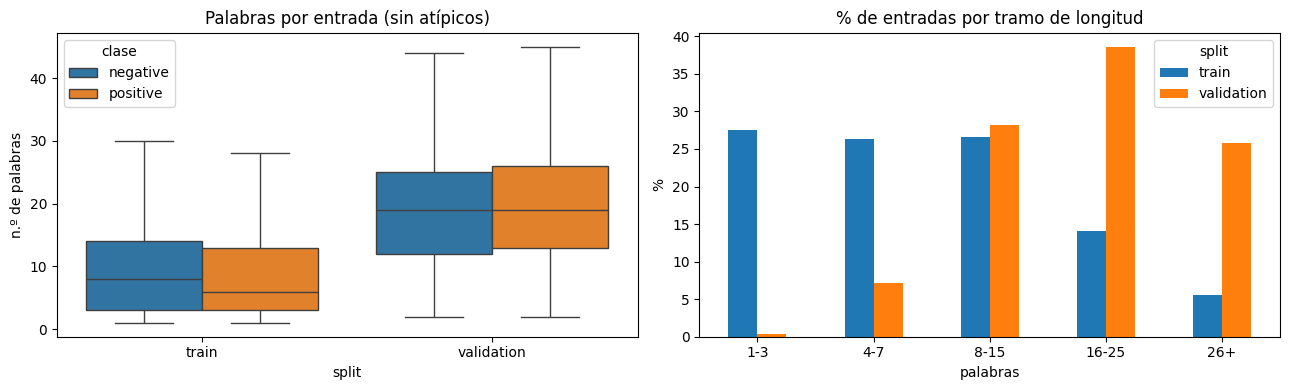

In [29]:
sst_df = pd.concat([pd.DataFrame({"split": s, "sentence": [t.strip() for t in sst2[s]["sentence"]], "label": sst2[s]["label"]})
                    for s in ["train", "validation"]], ignore_index=True)
sst_df["n_pal"] = sst_df["sentence"].str.split().str.len()
sst_df["clase"] = sst_df["label"].map(dict(enumerate(sst_labels)))

resumen = sst_df.groupby("split").agg(ejemplos=("label", "size"), pct_positivos=("label", lambda x: round(100 * x.mean(), 1)),
                                      palabras_media=("n_pal", "mean"), mediana=("n_pal", "median"), maximo=("n_pal", "max"),
                                      pct_hasta_3_palabras=("n_pal", lambda x: round(100 * (x <= 3).mean(), 1))).round(1)
display(resumen)
print(f"El test oficial tiene {len(sst2['test'])} oraciones SIN etiqueta (label = -1): no sirve para evaluar.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=sst_df, x="split", y="n_pal", hue="clase", showfliers=False, ax=ax[0])
ax[0].set_title("Palabras por entrada (sin atípicos)"); ax[0].set_ylabel("n.º de palabras")
tramos = pd.cut(sst_df["n_pal"], [0, 3, 7, 15, 25, 1000], labels=["1-3", "4-7", "8-15", "16-25", "26+"])
(pd.crosstab(sst_df["split"], tramos, normalize="index") * 100).T.plot(kind="bar", ax=ax[1], rot=0)
ax[1].set_title("% de entradas por tramo de longitud"); ax[1].set_ylabel("%"); ax[1].set_xlabel("palabras")
plt.tight_layout(); plt.show()

#### b) Ejemplos que ayudan a entender el problema

In [30]:
pd.set_option("display.max_colwidth", 150)
tr = sst_df[sst_df.split == "train"]; va = sst_df[sst_df.split == "validation"]
RX_NEG = r"(?:\bnot\b|n't|\bnever\b|\bno\b)"
RX_CON = r"\b(?:but|however|although|though|yet)\b"

print("== Fragmentos de 1-2 palabras del train (nodos del árbol sintáctico) ==")
display(tr[tr.n_pal <= 2].sample(6, random_state=SEED)[["sentence", "clase"]])
print("== Oraciones completas de validation ==")
display(va.sample(4, random_state=SEED)[["sentence", "clase"]])
for nombre, rx in [("con negación", RX_NEG), ("con contraste (but, however, although…)", RX_CON)]:
    sub = va[va.sentence.str.contains(rx, regex=True)]
    print(f"== Oraciones de validation {nombre}: {len(sub)} de {len(va)} ==")
    display(sub.sample(min(4, len(sub)), random_state=SEED)[["sentence", "clase"]])

# ¿Con qué frecuencia aparecen estas señales y se reparten igual entre clases?
señales = {"negación": RX_NEG, "contraste": RX_CON, "signo !": r"!", "signo ?": r"\?"}
filas = []
for nombre, rx in señales.items():
    m = sst_df["sentence"].str.contains(rx, regex=True)
    for s in ["train", "validation"]:
        d = sst_df["split"] == s
        filas.append({"señal": nombre, "partición": s, "% de entradas": round(100 * m[d].mean(), 1),
                      "% en negativas": round(100 * m[d & (sst_df.label == 0)].mean(), 1),
                      "% en positivas": round(100 * m[d & (sst_df.label == 1)].mean(), 1)})
display(pd.DataFrame(filas))

== Fragmentos de 1-2 palabras del train (nodos del árbol sintáctico) ==


,sentence,clase
64415,naturalistic,positive
66217,perpetually wasted,negative
22485,technical triumph,positive
51646,limply,negative
39228,uncanny tale,positive
44770,utter authority,negative


== Oraciones completas de validation ==


,sentence,clase
68143,it confirms fincher 's status as a film maker who artfully bends technical know-how to the service of psychological insight .,positive
67668,too much of it feels unfocused and underdeveloped .,negative
67731,a great ensemble cast ca n't lift this heartfelt enterprise out of the familiar .,negative
68128,"prurient playthings aside , there 's little to love about this english trifle .",negative


== Oraciones de validation con negación: 164 de 872 ==


,sentence,clase
68073,it 's everything you do n't go to the movies for .,negative
67980,burns never really harnesses to full effect the energetic cast .,negative
68046,not since tom cruise in risky business has an actor made such a strong impression in his underwear .,positive
67684,"with the exception of some fleetingly amusing improvisations by cedric the entertainer as perry 's boss , there is n't a redeeming moment here .",negative


== Oraciones de validation con contraste (but, however, although…): 130 de 872 ==


,sentence,clase
67751,"however it may please those who love movies that blare with pop songs , young science fiction fans will stomp away in disgust .",negative
67609,"/ but daphne , you 're too buff / fred thinks he 's tough / and velma - wow , you 've lost weight !",negative
67451,"does paint some memorable images ... , but makhmalbaf keeps her distance from the characters",positive
67542,"morton uses her face and her body language to bring us morvern 's soul , even though the character is almost completely deadpan .",positive


,señal,partición,% de entradas,% en negativas,% en positivas
0,negación,train,8.5,13.0,4.9
1,negación,validation,18.8,24.3,13.5
2,contraste,train,4.9,5.0,4.7
3,contraste,validation,14.9,16.1,13.7
4,signo !,train,0.2,0.1,0.2
5,signo !,validation,0.8,0.5,1.1
6,signo ?,train,0.3,0.5,0.1
7,signo ?,validation,1.4,2.1,0.7


#### c) Vocabulario: ¿qué palabras separan lo positivo de lo negativo?
Se calcula el **log-odds** de cada palabra frecuente: $\log\frac{P(w\mid\text{pos})}{P(w\mid\text{neg})}$ (con suavizado de +1). Valores muy positivos = palabra típica de reseñas positivas; muy negativos = típica de negativas. Se quitan las *stop words* para ver palabras con contenido (esto elimina también "not", que ya analizamos arriba).

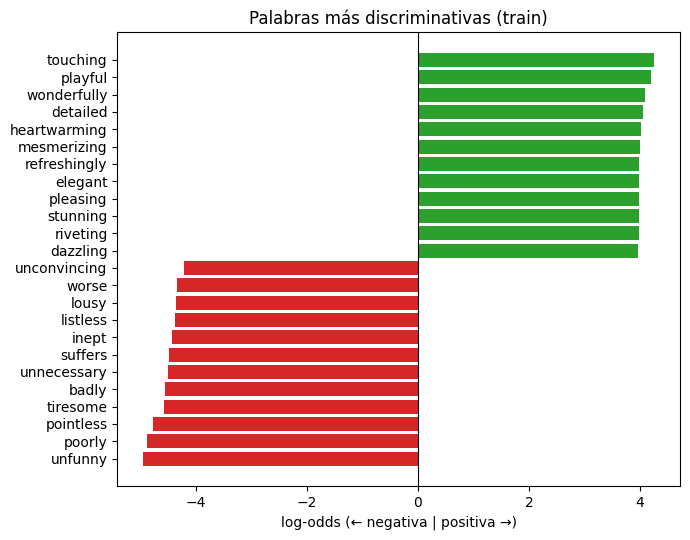

Vocabulario del train: 14,816 palabras distintas | tokens de validation fuera del vocabulario del train: 5.7%


In [31]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
tr_txt, y_tr = tr["sentence"].tolist(), tr["label"].to_numpy()
cv = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS), min_df=20, token_pattern=r"(?u)\b[a-z][a-z']+\b")
X = cv.fit_transform(tr_txt)
pos = np.asarray(X[y_tr == 1].sum(0)).ravel() + 1; neg = np.asarray(X[y_tr == 0].sum(0)).ravel() + 1
logodds = np.log(pos / pos.sum()) - np.log(neg / neg.sum())
palabras = np.array(cv.get_feature_names_out())
orden = np.argsort(logodds); sel = np.r_[orden[:12], orden[-12:]]
plt.figure(figsize=(7, 5.5))
plt.barh(palabras[sel], logodds[sel], color=["tab:red"] * 12 + ["tab:green"] * 12)
plt.axvline(0, color="k", lw=.8); plt.xlabel("log-odds (← negativa | positiva →)"); plt.title("Palabras más discriminativas (train)")
plt.tight_layout(); plt.show()

# Vocabulario y palabras fuera de vocabulario (OOV) de validation respecto al train
vocab_tr = {w for t in tr_txt for w in t.lower().split()}
toks_va = [w for t in va["sentence"] for w in t.lower().split()]
oov = float(np.mean([w not in vocab_tr for w in toks_va]))
print(f"Vocabulario del train: {len(vocab_tr):,} palabras distintas | tokens de validation fuera del vocabulario del train: {100 * oov:.1f}%")

#### d) Calidad de los datos: duplicados, conflictos y solapamiento
Tres chequeos de calidad. Además, se muestra con un ejemplo real **por qué separar el dev del `train` al azar produciría fuga de datos**: una sola oración larga contiene dentro de sí muchas otras entradas del `train`.

In [32]:
tr_t = tr["sentence"].str.lower(); va_t = va["sentence"].str.lower()
dup = int(tr_t.duplicated().sum())
conflictos = int((tr.assign(t=tr_t).groupby("t")["label"].nunique() > 1).sum())
solap = len(set(tr_t) & set(va_t))
print(f"Textos repetidos dentro del train: {dup} | textos con etiquetas contradictorias: {conflictos}")
print(f"Textos que están a la vez en train y validation: {solap} (si es ~0, validation es independiente del train)")

# Anidamiento: ¿cuántas entradas del train están contenidas dentro de una misma oración larga del train?
ej = tr[tr.n_pal >= 25].iloc[0]["sentence"]
dentro = tr[tr["sentence"].apply(lambda p: len(p) > 3 and p != ej and p in ej)]
print(f"\nOración larga del train:\n  «{ej}»")
print(f"Entradas del train contenidas dentro de ella: {len(dentro)} (con ≥3 palabras: {int((dentro.n_pal >= 3).sum())}). Algunas:")
display(dentro.sort_values("n_pal", ascending=False).head(6)[["sentence", "clase"]])

Textos repetidos dentro del train: 371 | textos con etiquetas contradictorias: 5
Textos que están a la vez en train y validation: 0 (si es ~0, validation es independiente del train)

Oración larga del train:
  «demonstrates that the director of such hollywood blockbusters as patriot games can still turn out a small , personal film with an emotional wallop .»
Entradas del train contenidas dentro de ella: 21 (con ≥3 palabras: 12). Algunas:


,sentence,clase
54137,"demonstrates that the director of such hollywood blockbusters as patriot games can still turn out a small , personal film with an emotional wallop",positive
45104,"that the director of such hollywood blockbusters as patriot games can still turn out a small , personal film with an emotional wallop",positive
38803,"the director of such hollywood blockbusters as patriot games can still turn out a small , personal film with an emotional wallop",positive
12371,"blockbusters as patriot games can still turn out a small , personal film with an emotional wallop",positive
19612,"as patriot games can still turn out a small , personal film with an emotional wallop",positive
42671,"patriot games can still turn out a small , personal film with an emotional wallop",positive


#### e) Qué aprendemos y cómo afecta al modelado

| Hallazgo  | Decisión que justifica |
|---|---|
| Clases casi balanceadas | Accuracy es una métrica válida; F1 como complemento; no hace falta reponderar |
| `train` = frases y fragmentos; `validation` = oraciones completas | Se evalúa en oraciones completas (el uso real); el modelo ve mucha variedad de longitudes |
| Una oración larga contiene decenas de entradas del `train` | Fuga de datos si el dev se saca del `train` al azar → el dev sale de la `validation` oficial |
| Negaciones y contrastes son frecuentes y aparecen en ambas clases | La suma de palabras no basta: se necesita un modelo con **contexto** (Transformer) frente a un modelo de bolsa de palabras |
| Test oficial sin etiquetas | `validation` se divide 50/50 en dev y prueba |

### 1.2 Tokenización y particiones

In [33]:
c = CFG["sst2"]
sst_tok = AutoTokenizer.from_pretrained(c["model"])

def tok_sst(batch):
    return sst_tok(batch["sentence"], truncation=True, max_length=c["max_len"])

_drop = ["sentence", "idx"]
sst_train = sst2["train"].map(tok_sst, batched=True, remove_columns=_drop)

# validation oficial -> dev / prueba (50/50 estratificado). Se parte primero el texto crudo para poder analizar errores luego.
_v = sst2["validation"].train_test_split(test_size=0.5, seed=SEED, stratify_by_column="label")
sst_dev_raw, sst_test_raw = _v["train"], _v["test"]
sst_dev = sst_dev_raw.map(tok_sst, batched=True, remove_columns=_drop)
sst_test = sst_test_raw.map(tok_sst, batched=True, remove_columns=_drop)
print("train / dev / prueba:", len(sst_train), len(sst_dev), len(sst_test))
print(sst_tok.decode(sst_train[0]["input_ids"]))

# ¿max_len=128 trunca algo? (medido con el tokenizador real)
_vl = sst2["validation"].map(lambda b: sst_tok(b["sentence"]), batched=True)
length_report([len(x) for x in _vl["input_ids"]], c["max_len"], "SST-2 validation (tokens, sin truncar)")

# Baseline: predecir siempre la clase mayoritaria del train
sst_major = int(np.bincount(sst2["train"]["label"]).argmax())
sst_baseline = float(np.mean(np.array(sst_test_raw["label"]) == sst_major))
print(f"Baseline clase mayoritaria ({sst_labels[sst_major]}): accuracy en prueba = {sst_baseline:.4f}")

train / dev / prueba: 67349 436 436
[CLS] hide new secretions from the parental units [SEP]
SST-2 validation (tokens, sin truncar): mediana=24 | p95=44 | p99=51 | máx=55 | truncados con max_len=128: 0.00%
Baseline clase mayoritaria (positive): accuracy en prueba = 0.5092


### 1.3 Modelo, métricas y *trainer*

In [34]:
def metrics_cls(p):
    preds = np.argmax(p.predictions, axis=-1)
    return {"accuracy": accuracy_score(p.label_ids, preds), "f1": f1_score(p.label_ids, preds)}

def build_sst(hp, train_ds, eval_ds, epochs, out, final, seed=SEED):
    model = AutoModelForSequenceClassification.from_pretrained(
        CFG["sst2"]["model"], num_labels=2,
        id2label={0: "NEGATIVE", 1: "POSITIVE"}, label2id={"NEGATIVE": 0, "POSITIVE": 1})
    args = make_args(TrainingArguments, out, hp, epochs, final, "eval_accuracy", USE_FP16, seed=seed)
    return Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                   data_collator=DataCollatorWithPadding(sst_tok), compute_metrics=metrics_cls,
                   callbacks=callbacks_for(final, epochs), **{TOK_KW: sst_tok})

### 1.4 Búsqueda de hiperparámetros (muestra pequeña)
Las gráficas muestran el efecto marginal de cada hiperparámetro sobre la accuracy del dev.

Reanudando búsqueda: 10 corridas ya hechas


,trial,lr,bs,weight_decay,warmup,scheduler,label_smoothing,loss,accuracy,f1,train_loss,minutos,accuracy_std,n_semillas
0,0,0.00003,32,0.01,0.10,linear,0.0,0.3500,0.8544,0.8612,0.3128,0.7457,0.0011,2
1,1,0.00001,16,0.10,0.06,linear,0.0,0.3638,0.8532,0.8581,0.3441,1.1344,0.0000,2
2,3,0.00001,16,0.00,0.00,linear,0.0,0.3701,0.8532,0.8578,0.3347,0.3993,0.0000,1
3,2,0.00002,64,0.00,0.10,linear,0.1,0.4478,0.8486,0.8559,0.4580,0.2257,0.0000,1
4,6,0.00003,32,0.00,0.00,cosine,0.0,0.3803,0.8486,0.8565,0.2926,0.2649,0.0000,1
5,7,0.00001,32,0.00,0.06,cosine,0.1,0.4430,0.8417,0.8456,0.4566,0.2627,0.0000,1
6,4,0.00010,16,0.10,0.10,cosine,0.0,0.5289,0.8394,0.8465,0.2837,0.4010,0.0000,1
7,5,0.00005,64,0.01,0.00,linear,0.1,0.4312,0.8349,0.8487,0.3924,0.1995,0.0000,1


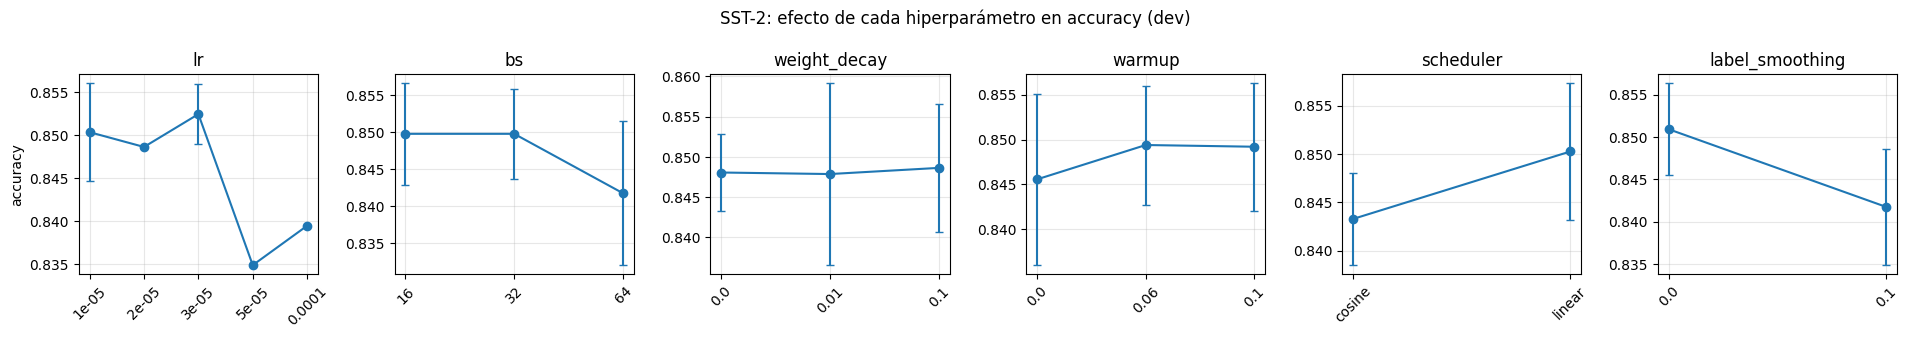

Top 5 configuraciones (media sobre las semillas disponibles):


,trial,lr,bs,weight_decay,warmup,scheduler,label_smoothing,accuracy,accuracy_std,n_semillas
0,0,0.00003,32,0.01,0.10,linear,0.0,0.8544,0.0011,2
1,1,0.00001,16,0.10,0.06,linear,0.0,0.8532,0.0000,2
2,3,0.00001,16,0.00,0.00,linear,0.0,0.8532,0.0000,1
3,2,0.00002,64,0.00,0.10,linear,0.1,0.8486,0.0000,1
4,6,0.00003,32,0.00,0.00,cosine,0.0,0.8486,0.0000,1


Mejor configuración: {'lr': 3e-05, 'bs': 32, 'weight_decay': 0.01, 'warmup': 0.1, 'scheduler': 'linear', 'label_smoothing': 0.0} -> accuracy = 0.8544


In [35]:
c = CFG["sst2"]
sst_hp, sst_hp_raw = run_hp_search("sst2", build_sst, subsample(sst_train, c["search_train"]), subsample(sst_dev, c["search_eval"]),
                                   SPACE["sst2"], DEFAULTS["sst2"], c["n_trials"], c["search_epochs"], "accuracy", c["confirm_top"])
display(sst_hp)
plot_hp_effects(sst_hp_raw, SPACE["sst2"], "accuracy", "SST-2")
sst_best_hp, sst_best_trial = pick_best_hp(sst_hp, SPACE["sst2"], "accuracy")

### 1.5 Entrenamiento final (mejor configuración) y evaluación en prueba

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.178362,0.281566,0.896789,0.897494
2,0.101719,0.367062,0.887615,0.895075
3,0.069005,0.394373,0.892202,0.896703


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

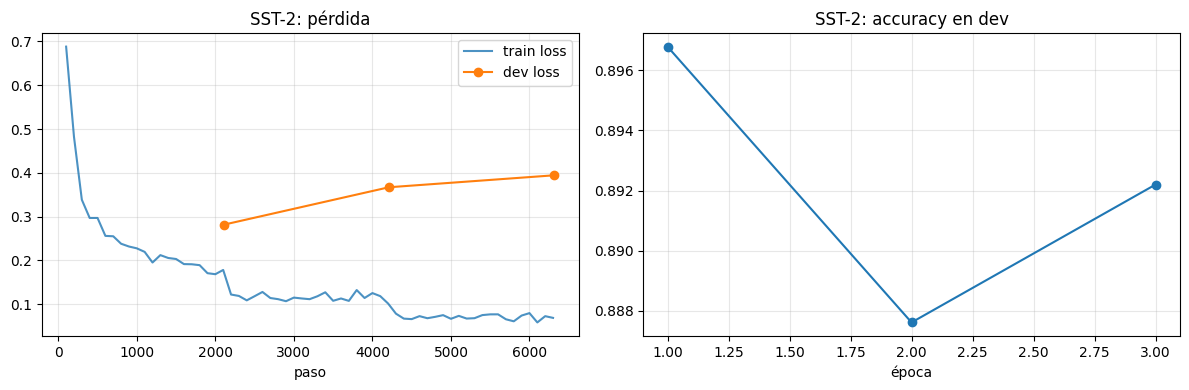

[transformers] early stopping required metric_for_best_model, but did not find eval_accuracy so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.069005,0.281566,3,0.896789,0.897494


[transformers] early stopping required metric_for_best_model, but did not find eval_accuracy so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.069005,0.199312,3,0.924312,0.923434


{'test_loss': 0.1993119716644287, 'test_accuracy': 0.9243119266055045, 'test_f1': 0.9234338747099768}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [36]:
c = CFG["sst2"]
set_seed(SEED)
sst_dir = f"{OUT}/sst2_final_{hp_tag(sst_best_trial, sst_best_hp)}"
sst_trainer = build_sst(sst_best_hp, subsample(sst_train, c["max_final_train"]), sst_dev,
                        c["final_epochs"], sst_dir, final=True)
fit(sst_trainer, sst_dir)
plot_history(sst_trainer, "accuracy", "SST-2")
sst_dev_m = sst_trainer.evaluate(sst_dev, metric_key_prefix="dev")
sst_test_m = sst_trainer.evaluate(sst_test, metric_key_prefix="test")   # única evaluación en prueba
print(sst_test_m)
sst_trainer.save_model(f"{OUT}/sst2_best")
RESULTS["sst2"] = dict(tarea="Clasificación de secuencias", dataset="GLUE/SST-2", modelo=c["model"],
                       mejores_hp=sst_best_hp, metrica_principal="accuracy (test)",
                       valor=round(sst_test_m["test_accuracy"], 4), dev=round(sst_dev_m["dev_accuracy"], 4),
                       baseline=round(sst_baseline, 4), baseline_nombre="clase mayoritaria",
                       extra=f"F1={sst_test_m['test_f1']:.4f}")

### 1.6 Análisis de errores

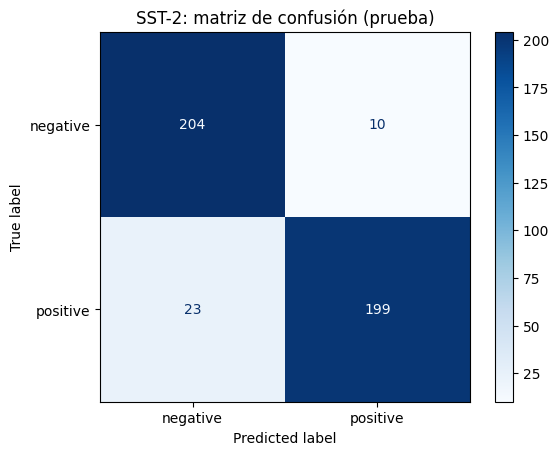

Errores: 33 de 436. Los más confiados (el modelo estaba 'seguro' y falló):

real=positive pred=negative conf=0.99 | harrison 's flowers puts its heart in the right place , but its brains are in no particular place at all .
real=positive pred=negative conf=0.99 | on the heels of the ring comes a similarly morose and humorless horror movie that , although flawed , is to be commended for its straight-ahead approach to creepiness .
real=positive pred=negative conf=0.99 | this surreal gilliam-esque film is also a troubling interpretation of ecclesiastes .
real=negative pred=positive conf=0.98 | the longer the movie goes , the worse it gets , but it 's actually pretty good in the first few minutes .
real=negative pred=positive conf=0.97 | you wo n't like roger , but you will quickly recognize him .
real=negative pred=positive conf=0.95 | sit through this one , and you wo n't need a magic watch to stop time ; your dvd player will do it for you .
real=positive pred=negative conf=0.94 | hilario

In [37]:
pred = sst_trainer.predict(sst_test)
yhat = np.argmax(pred.predictions, -1)
ConfusionMatrixDisplay.from_predictions(pred.label_ids, yhat, display_labels=sst_labels, cmap="Blues")
plt.title("SST-2: matriz de confusión (prueba)"); plt.show()

probs = torch.softmax(torch.tensor(pred.predictions), -1).numpy()
wrong = np.where(yhat != pred.label_ids)[0]
print(f"Errores: {len(wrong)} de {len(yhat)}. Los más confiados (el modelo estaba 'seguro' y falló):\n")
for i in sorted(wrong, key=lambda j: -probs[j].max())[:8]:
    print(f"real={sst_labels[pred.label_ids[i]]:8s} pred={sst_labels[yhat[i]]:8s} conf={probs[i].max():.2f} | {sst_test_raw[int(i)]['sentence'].strip()}")

## 2. Etiquetado de secuencias — CoNLL-2003 (NER)

**Dataset:** `lhoestq/conll2003` (noticias de Reuters).

| Aspecto | Descripción |
|---|---|
| **Dominio** | Noticias en inglés |
| **Utilidad** | Extraer automáticamente personas, organizaciones, lugares y otras entidades (indexación de noticias, búsqueda semántica, relleno de bases de conocimiento, anonimización) |
| **Entrada** | `tokens`: lista de palabras de una oración |
| **Salida** | `ner_tags`: una etiqueta **por palabra** en formato BIO (`O`, `B-PER`, `I-PER`, `B-ORG`, `I-ORG`, `B-LOC`, `I-LOC`, `B-MISC`, `I-MISC`) |
| **Tipo de problema** | Etiquetado de secuencias: clasificación **a nivel de token** |
| **Modelo** | `distilbert-base-cased` + cabeza de clasificación por token |
| **Métrica** | Precision / Recall / F1 **a nivel de entidad** (`seqeval`) |

Se usa *cased* porque en NER la mayúscula inicial es una pista fuerte de que una palabra es un nombre propio.

In [38]:
conll = load_dataset("lhoestq/conll2003")
print(conll)

NER_LABELS = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]

feat = conll["train"].features["ner_tags"]
if hasattr(feat, "feature") and hasattr(feat.feature, "names"):
    # Formato clásico: ClassLabel con nombres
    ner_labels = feat.feature.names
else:
    ner_labels = NER_LABELS
    primero = conll["train"][0]["ner_tags"][0]
    if isinstance(primero, str):
        # Etiquetas como texto: convertirlas a ids
        l2i = {l: i for i, l in enumerate(NER_LABELS)}
        conll = conll.map(lambda ex: {"ner_tags": [l2i[t] for t in ex["ner_tags"]]})

# Comprobaciones para no entrenar con etiquetas mal asignadas
ej = conll["train"][0]
assert ej["tokens"][0] == "EU" and ner_labels[ej["ner_tags"][0]] == "B-ORG", "Orden de etiquetas inesperado"
assert max(max(t) for t in conll["train"]["ner_tags"]) < len(ner_labels)

print("Etiquetas:", ner_labels)
display(split_overview(conll))

dataset_infos.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  281kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  259kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
Etiquetas: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


,partición,ejemplos,columnas
0,train,14041,"id, tokens, pos_tags, chunk_tags, ner_tags"
1,validation,3250,"id, tokens, pos_tags, chunk_tags, ner_tags"
2,test,3453,"id, tokens, pos_tags, chunk_tags, ner_tags"


### 2.1 Análisis exploratorio

In [39]:
def render_tags(tokens, tags):
    # reconstruye la oración marcando las entidades: [Texto|TIPO]
    out, cur, cur_t = [], [], None
    for tok, t in zip(tokens, tags):
        if t == "O":
            if cur: out.append(f"[{' '.join(cur)}|{cur_t}]"); cur, cur_t = [], None
            out.append(tok)
        elif t.startswith("B-") or (cur_t != t[2:]):
            if cur: out.append(f"[{' '.join(cur)}|{cur_t}]")
            cur, cur_t = [tok], t[2:]
        else:
            cur.append(tok)
    if cur: out.append(f"[{' '.join(cur)}|{cur_t}]")
    return " ".join(out)

def render_entities(ex):
    return render_tags(ex["tokens"], [ner_labels[i] for i in ex["ner_tags"]])

def show_ner(ex):
    return pd.DataFrame({"token": ex["tokens"], "etiqueta": [ner_labels[i] for i in ex["ner_tags"]]}).T

display(show_ner(conll["train"][0]))
for i in [0, 3, 12]:
    print(render_entities(conll["train"][i]))

,0,1,2,3,4,5,6,7,8
token,EU,rejects,German,call,to,boycott,British,lamb,.
etiqueta,B-ORG,O,B-MISC,O,O,O,B-MISC,O,O


[EU|ORG] rejects [German|MISC] call to boycott [British|MISC] lamb .
The [European Commission|ORG] said on Thursday it disagreed with [German|MISC] advice to consumers to shun [British|MISC] lamb until scientists determine whether mad cow disease can be transmitted to sheep .
Only [France|LOC] and [Britain|LOC] backed [Fischler|PER] 's proposal .


partición,test,train,validation
etiqueta,,,
B-LOC,1668,7140,1837
B-MISC,702,3438,922
B-ORG,1661,6321,1341
B-PER,1617,6600,1842
I-LOC,257,1157,257
I-MISC,216,1155,346
I-ORG,835,3704,751
I-PER,1156,4528,1307
O,38323,169578,42759


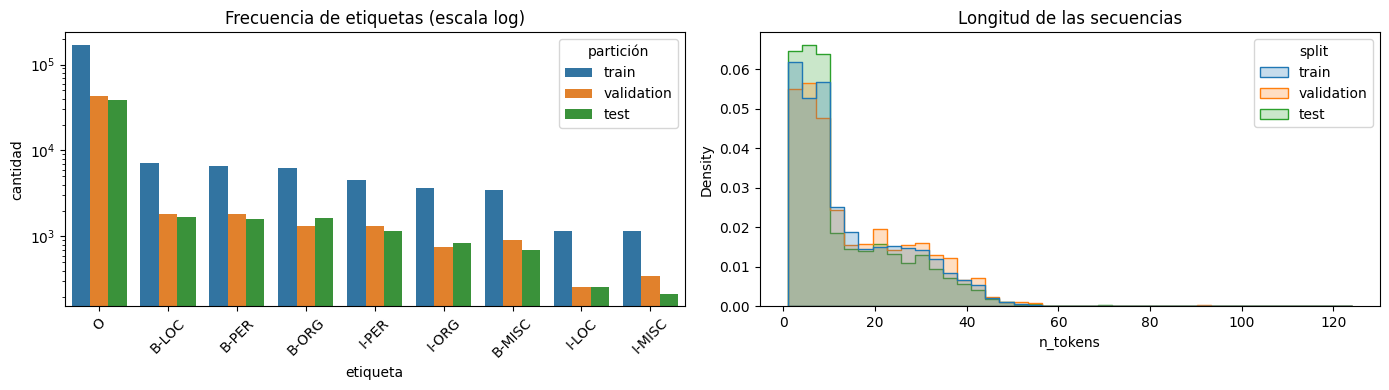

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,3453.0,13.45,11.55,1.0,5.0,9.0,20.0,124.0
train,14041.0,14.50,11.60,1.0,6.0,10.0,22.0,113.0
validation,3250.0,15.80,12.60,1.0,7.0,11.0,24.0,109.0



• 'O' es el 83.3% de los tokens de train: un modelo que prediga todo 'O' tendría esa accuracy por token y F1 de entidad = 0.
• Etiquetas más raras en train: {'I-MISC': 1155, 'I-LOC': 1157, 'B-MISC': 3438}


In [40]:
rows = []
for split in conll:
    cnt = pd.Series([t for seq in conll[split]["ner_tags"] for t in seq]).value_counts()
    for k, v in cnt.items():
        rows.append({"partición": split, "etiqueta": ner_labels[k], "cantidad": int(v)})
ner_dist = pd.DataFrame(rows)
ner_pivot = ner_dist.pivot(index="etiqueta", columns="partición", values="cantidad").fillna(0).astype(int)
display(ner_pivot)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=ner_dist, x="etiqueta", y="cantidad", hue="partición", ax=ax[0])
ax[0].set_yscale("log"); ax[0].tick_params(axis="x", rotation=45); ax[0].set_title("Frecuencia de etiquetas (escala log)")

ner_len = pd.DataFrame([{"split": s, "n_tokens": len(x)} for s in conll for x in conll[s]["tokens"]])
sns.histplot(data=ner_len, x="n_tokens", hue="split", bins=40, element="step", stat="density", common_norm=False, ax=ax[1])
ax[1].set_title("Longitud de las secuencias"); plt.tight_layout(); plt.show()
display(ner_len.groupby("split")["n_tokens"].describe().round(2))

# Cifras que sustentan la interpretación
pct_O = 100 * ner_pivot.loc["O", "train"] / ner_pivot["train"].sum()
print(f"\n• 'O' es el {pct_O:.1f}% de los tokens de train: un modelo que prediga todo 'O' tendría esa accuracy por token y F1 de entidad = 0.")
print("• Etiquetas más raras en train:", ner_pivot["train"].sort_values().head(3).to_dict())

#### a) Entidades (no etiquetas): cuántas hay, de qué tipo y de qué longitud
Las etiquetas BIO describen *palabras*; lo que realmente queremos extraer son **entidades** (secuencias de palabras). Aquí se reconstruyen las entidades completas a partir de las etiquetas, para contarlas por tipo y medir su longitud.

,oraciones,tokens,entidades,entidades por oración,% oraciones sin entidades
train,14041,203621,23499,1.67,20.7
validation,3250,51362,5942,1.83,19.8
test,3453,46435,5648,1.64,20.2


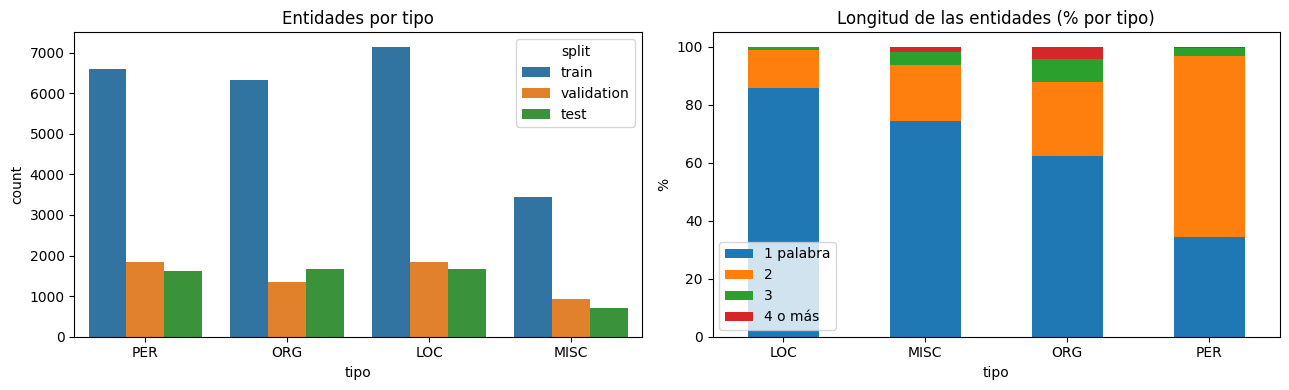

In [41]:
def extraer_entidades(tokens, tags):
    # [(tipo, texto)] a partir de etiquetas BIO
    spans, cur, cur_t = [], [], None
    for tok, t in zip(tokens, tags):
        if t == "O":
            if cur: spans.append((cur_t, " ".join(cur))); cur, cur_t = [], None
        elif t.startswith("B-") or cur_t != t[2:]:
            if cur: spans.append((cur_t, " ".join(cur)))
            cur, cur_t = [tok], t[2:]
        else:
            cur.append(tok)
    if cur: spans.append((cur_t, " ".join(cur)))
    return spans

filas = []
for s in conll:
    for i, (toks, tg) in enumerate(zip(conll[s]["tokens"], conll[s]["ner_tags"])):
        for tipo, texto in extraer_entidades(toks, [ner_labels[t] for t in tg]):
            filas.append((s, i, tipo, texto, len(texto.split())))
ent_df = pd.DataFrame(filas, columns=["split", "sent", "tipo", "texto", "n_tok"])

resumen = pd.DataFrame({s: {"oraciones": len(conll[s]), "tokens": sum(len(x) for x in conll[s]["tokens"]),
                             "entidades": int((ent_df.split == s).sum())} for s in conll}).T
resumen["entidades por oración"] = (resumen["entidades"] / resumen["oraciones"]).round(2)
resumen["% oraciones sin entidades"] = [round(100 * (1 - ent_df[ent_df.split == s]["sent"].nunique() / len(conll[s])), 1) for s in resumen.index]
display(resumen)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=ent_df, x="tipo", hue="split", order=["PER", "ORG", "LOC", "MISC"], ax=ax[0]); ax[0].set_title("Entidades por tipo")
largo = (pd.crosstab(ent_df["tipo"], ent_df["n_tok"].clip(upper=4), normalize="index") * 100).reindex(columns=[1, 2, 3, 4], fill_value=0)
largo.columns = ["1 palabra", "2", "3", "4 o más"]
largo.plot(kind="bar", stacked=True, ax=ax[1], rot=0); ax[1].set_title("Longitud de las entidades (% por tipo)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

#### b) Ejemplos: casos típicos y casos raros
Se muestran, con las entidades marcadas como `[texto|TIPO]`: la oración con **más entidades**, una **sin ninguna**, una **tabla deportiva** (muy frecuente en CoNLL, con muchos números) y una con una **organización de varias palabras**.

In [42]:
tr_d = conll["train"]
n_ent = ent_df[ent_df.split == "train"].groupby("sent").size()
con_ent = set(n_ent.index)
sin_ent = next(i for i in range(len(tr_d)) if i not in con_ent and len(tr_d[i]["tokens"]) >= 6)
es_num = lambda t: t.replace(".", "").replace(",", "").replace("-", "").isdigit()
deportiva = next((i for i, toks in enumerate(tr_d["tokens"]) if len(toks) >= 8 and sum(map(es_num, toks)) / len(toks) >= 0.3), None)
org_larga = ent_df[(ent_df.split == "train") & (ent_df.tipo == "ORG") & (ent_df.n_tok >= 3)]["sent"].iloc[0]

def mostrar(titulo, i):
    ex = tr_d[int(i)]
    print(f"--- {titulo} (oración {i}) ---"); print(render_entities(ex)); print()

mostrar("Más entidades", n_ent.idxmax()); mostrar("Sin entidades", sin_ent)
if deportiva is not None: mostrar("Tabla deportiva", deportiva)
mostrar("Organización de varias palabras", org_larga)

--- Más entidades (oración 8884) ---
Squad : [Alan Kelly|PER] , [Shay Given|PER] , [Denis Irwin|PER] , [Phil Babb|PER] , [Jeff Kenna|PER] , [Curtis Fleming|PER] , [Gary Breen|PER] , [Ian Harte|PER] , [Kenny Cunningham|PER] , [Steve Staunton|PER] , [Andy Townsend|PER] , [Ray Houghton|PER] , [Gareth Farrelly|PER] , [Alan McLoughlin|PER] , [Jason McAteer|PER] , [Alan Moore|PER] , [Keith O'Neill|PER] , [Tony Cascarino|PER] , [Niall Quinn|PER] , [David Kelly|PER] .

--- Sin entidades (oración 27) ---
The guitarist died of a drugs overdose in 1970 aged 27 .

--- Tabla deportiva (oración 248) ---
Jul 31 , Jul 31 , Jul 31 , Jul 31 ,

--- Organización de varias palabras (oración 16) ---
" What we have to be extremely careful of is how other countries are going to take [Germany|LOC] 's lead , " [Welsh National Farmers ' Union|ORG] ( [NFU|ORG] ) chairman [John Lloyd Jones|PER] said on [BBC radio|ORG] .



#### c) Mayúsculas: ¿por qué usamos un modelo *cased*?
Se mide, fuera de la primera palabra de cada oración (que siempre va en mayúscula), qué fracción de los tokens empieza con mayúscula según sean entidad o no. Si la diferencia es grande, la mayúscula es una pista que un modelo *uncased* desperdiciaría.

In [43]:
cnt = {"entidad": [0, 0], "no entidad (O)": [0, 0]}      # [total, con mayúscula inicial]
for toks, tg in zip(conll["train"]["tokens"], conll["train"]["ner_tags"]):
    for j, (t, y) in enumerate(zip(toks, tg)):
        if j == 0: continue
        k = "no entidad (O)" if ner_labels[y] == "O" else "entidad"
        cnt[k][0] += 1; cnt[k][1] += t[:1].isupper()
for k, (n, m) in cnt.items():
    print(f"{k:16s}: {100 * m / n:5.1f}% de los tokens empiezan con mayúscula ({m:,} de {n:,})")

entidad         :  97.6% de los tokens empiezan con mayúscula (27,484 de 28,156)
no entidad (O)  :   3.9% de los tokens empiezan con mayúscula (6,261 de 161,424)


#### d) Ambigüedad, entidades nuevas y calidad de las etiquetas


In [44]:
tr_e = ent_df[ent_df.split == "train"]
print("Entidades más frecuentes por tipo (train):")
display(tr_e.groupby("tipo")["texto"].agg(lambda s: ", ".join(f"{k} ({v})" for k, v in s.value_counts().head(6).items())).to_frame("top 6"))

tipos_por_texto = tr_e.groupby("texto")["tipo"].agg(lambda s: s.value_counts().to_dict())
multi = tipos_por_texto[tipos_por_texto.apply(len) > 1]
print(f"\nTextos con más de un tipo en el train: {len(multi)} de {tr_e['texto'].nunique():,} distintos ({100 * len(multi) / tr_e['texto'].nunique():.1f}%). Los más frecuentes:")
top = tr_e[tr_e.texto.isin(multi.index)]["texto"].value_counts().head(8).index
display(pd.DataFrame({"texto": top, "tipos (conteos)": [multi[t] for t in top]}))

vistos = set(tr_e["texto"])
for s in ["validation", "test"]:
    sub = ent_df[ent_df.split == s]; nuevo = ~sub["texto"].isin(vistos)
    por_tipo = (nuevo.groupby(sub["tipo"]).mean() * 100).round(1).to_dict()
    print(f"{s:10s}: {100 * nuevo.mean():.1f}% de las entidades NO aparecen en el train | por tipo: {por_tipo}")

def invalidas(etiquetas):
    n = 0
    for seq in etiquetas:
        prev = "O"
        for t in (ner_labels[i] for i in seq):
            if t.startswith("I-") and prev[2:] != t[2:]: n += 1
            prev = t
    return n
print("\nTransiciones BIO inválidas (I-X sin B-X/I-X previa):", {s: invalidas(conll[s]["ner_tags"]) for s in conll})

Entidades más frecuentes por tipo (train):


,top 6
tipo,
LOC,"U.S. (303), Germany (141), Britain (133), Australia (130), England (123), France (122)"
MISC,"Russian (92), German (80), British (73), French (59), Dutch (50), GMT (49)"
ORG,"Reuters (73), U.N. (35), NEW YORK (30), CHICAGO (30), OSCE (25), PUK (25)"
PER,"Clinton (70), Dole (36), Arafat (35), Yeltsin (32), Lebed (30), Dutroux (30)"



Textos con más de un tipo en el train: 132 de 8,082 distintos (1.6%). Los más frecuentes:


,texto,tipos (conteos)
0,NEW YORK,"{'LOC': 65, 'ORG': 30}"
1,London,"{'LOC': 61, 'ORG': 5}"
2,CHICAGO,"{'ORG': 30, 'LOC': 29}"
3,New York,"{'LOC': 35, 'ORG': 9}"
4,American,"{'MISC': 37, 'ORG': 1}"
5,Chicago,"{'LOC': 27, 'ORG': 5}"
6,Jordan,"{'LOC': 24, 'ORG': 7, 'PER': 1}"
7,Washington,"{'LOC': 26, 'PER': 3}"


validation: 32.0% de las entidades NO aparecen en el train | por tipo: {'LOC': 13.0, 'MISC': 20.3, 'ORG': 31.4, 'PER': 57.2}
test      : 46.0% de las entidades NO aparecen en el train | por tipo: {'LOC': 17.9, 'MISC': 32.3, 'ORG': 41.9, 'PER': 85.3}

Transiciones BIO inválidas (I-X sin B-X/I-X previa): {'train': 0, 'validation': 0, 'test': 0}


#### e) Qué aprendemos y cómo afecta al modelado

| Hallazgo (confírmalo con tus cifras) | Decisión que justifica |
|---|---|
| `O` es la gran mayoría de los tokens y muchas oraciones no tienen entidades | Accuracy por token es engañosa → **F1 a nivel de entidad** (`seqeval`) |
| Las entidades empiezan con mayúscula mucho más a menudo que los demás tokens | Modelo **cased** (`distilbert-base-cased`) |
| Hay entidades de varias palabras (sobre todo `ORG` y `PER`) | Hay que predecir la **estructura** BIO, no solo una clase por palabra |
| Una fracción importante de las entidades de test es nueva | La memorización por palabra (baseline) tiene un techo bajo; el contexto importa |
| Hay textos ambiguos entre `LOC`/`ORG` (deportes) | Se espera confusión `ORG` ↔ `LOC`; se revisa en el análisis de errores |
| Las tablas deportivas están llenas de números y nombres | Un tipo de texto distinto del resto de las noticias; revísalo si el rendimiento cae |
| Etiquetas BIO consistentes (0 transiciones inválidas, si lo confirma la salida) | Se puede alinear y evaluar sin corregir el formato |

### 2.2 Tokenización con alineación de etiquetas

In [45]:
ner_tok = AutoTokenizer.from_pretrained(CFG["ner"]["model"])
NER_MAXLEN = CFG["ner"]["max_len"]

def tok_align(batch):
    enc = ner_tok(batch["tokens"], truncation=True, is_split_into_words=True, max_length=NER_MAXLEN)
    all_labels = []
    for i, word_tags in enumerate(batch["ner_tags"]):
        prev, lab = None, []
        for w in enc.word_ids(batch_index=i):
            if w is None:        lab.append(-100)             # tokens especiales
            elif w != prev:      lab.append(word_tags[w])     # primera subpalabra de la palabra
            else:                lab.append(-100)             # subpalabras siguientes
            prev = w
        all_labels.append(lab)
    enc["labels"] = all_labels
    return enc

ner_enc = conll.map(tok_align, batched=True, remove_columns=conll["train"].column_names)

# Verificación visual de la alineación
ex = ner_enc["train"][0]
print(list(zip(ner_tok.convert_ids_to_tokens(ex["input_ids"]), ex["labels"])))

# ¿Se trunca algo con max_len=256? ¿Cuántas subpalabras por palabra?
length_report([len(x) for x in ner_enc["train"]["input_ids"]], NER_MAXLEN, "CoNLL train (subpalabras)")
n_words = sum(len(x) for x in conll["train"]["tokens"]); n_sub = sum(len(x) for x in ner_enc["train"]["input_ids"])
print(f"Subpalabras por palabra: {n_sub / n_words:.2f} (incluye [CLS]/[SEP])")

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

[('[CLS]', -100), ('EU', 3), ('rejects', 0), ('German', 7), ('call', 0), ('to', 0), ('boycott', 0), ('British', 7), ('la', 0), ('##mb', -100), ('.', 0), ('[SEP]', -100)]
CoNLL train (subpalabras): mediana=17 | p95=47 | p99=58 | máx=173 | truncados con max_len=256: 0.00%
Subpalabras por palabra: 1.48 (incluye [CLS]/[SEP])


### 2.3 Modelo, métricas, baseline y *trainer*

In [46]:
seqeval = evaluate.load("seqeval")

def metrics_ner(p):
    logits, labels = p
    preds = np.argmax(logits, axis=-1)
    y_pred = [[ner_labels[a] for a, b in zip(pr, lb) if b != -100] for pr, lb in zip(preds, labels)]
    y_true = [[ner_labels[b] for a, b in zip(pr, lb) if b != -100] for pr, lb in zip(preds, labels)]
    r = seqeval.compute(predictions=y_pred, references=y_true)
    return {"precision": r["overall_precision"], "recall": r["overall_recall"],
            "f1": r["overall_f1"], "accuracy": r["overall_accuracy"]}

def build_ner(hp, train_ds, eval_ds, epochs, out, final, seed=SEED):
    model = AutoModelForTokenClassification.from_pretrained(
        CFG["ner"]["model"], num_labels=len(ner_labels),
        id2label=dict(enumerate(ner_labels)), label2id={l: i for i, l in enumerate(ner_labels)})
    args = make_args(TrainingArguments, out, hp, epochs, final, "eval_f1", USE_FP16, seed=seed)
    return Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                   data_collator=DataCollatorForTokenClassification(ner_tok), compute_metrics=metrics_ner,
                   callbacks=callbacks_for(final, epochs), **{TOK_KW: ner_tok})

# Baseline "memorización": a cada palabra se le asigna su etiqueta más frecuente en train (las desconocidas -> O)
from collections import Counter, defaultdict
_cnt = defaultdict(Counter)
for toks, tags in zip(conll["train"]["tokens"], conll["train"]["ner_tags"]):
    for w, t in zip(toks, tags): _cnt[w][t] += 1
_pred = [[ner_labels[_cnt[w].most_common(1)[0][0]] if w in _cnt else "O" for w in toks] for toks in conll["test"]["tokens"]]
_ref = [[ner_labels[t] for t in tags] for tags in conll["test"]["ner_tags"]]
ner_baseline = seqeval.compute(predictions=_pred, references=_ref)["overall_f1"]
print(f"Baseline memorización: F1 de entidad en prueba = {ner_baseline:.4f}")

Baseline memorización: F1 de entidad en prueba = 0.5488


### 2.4 Búsqueda de hiperparámetros (muestra pequeña)

model.safetensors: reconstructing file:   0%|          |  0.00B /  263MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
100,0.586085
200,0.105460
300,0.068661


Training Loss,Validation Loss,Step,Precision,Recall,F1,Accuracy
0.068661,0.065893,376,0.880507,0.891304,0.885873,0.980670


... (43 outputs left out)

Step,Training Loss
100,0.368471
200,0.133591
300,0.118629
400,0.080022
500,0.046262
600,0.044066
700,0.042093


Training Loss,Validation Loss,Step,Precision,Recall,F1,Accuracy
0.042093,0.062871,750,0.894562,0.898551,0.896552,0.982925


{'trial': 3, 'lr': 0.0001, 'bs': 8, 'weight_decay': 0.0, 'warmup': 0.0, 'scheduler': 'linear', 'seed': 7, 'train_loss': 0.1138, 'minutos': 0.4946, 'loss': 0.0629, 'precision': 0.8946, 'recall': 0.8986, 'f1': 0.8966, 'accuracy': 0.9829}


,trial,lr,bs,weight_decay,warmup,scheduler,loss,precision,recall,f1,accuracy,train_loss,minutos,f1_std,n_semillas
0,5,0.00010,8,0.01,0.10,cosine,0.0645,0.8969,0.9013,0.8991,0.9823,0.1523,0.9611,0.0063,2
1,3,0.00010,8,0.00,0.00,linear,0.0636,0.8948,0.9005,0.8976,0.9827,0.1144,0.9756,0.0011,2
2,7,0.00005,8,0.00,0.06,linear,0.0643,0.8931,0.8991,0.8961,0.9823,0.1571,0.4839,0.0000,1
3,0,0.00005,16,0.01,0.10,linear,0.0659,0.8805,0.8913,0.8859,0.9807,0.2127,0.3441,0.0000,1
4,2,0.00003,8,0.10,0.00,linear,0.0711,0.8731,0.8857,0.8794,0.9800,0.1469,0.4796,0.0000,1
5,4,0.00003,32,0.10,0.00,linear,0.0930,0.8325,0.8367,0.8346,0.9723,0.2837,0.1922,0.0000,1
6,6,0.00001,8,0.10,0.06,cosine,0.0974,0.8201,0.8283,0.8242,0.9715,0.2782,0.4926,0.0000,1
7,1,0.00001,8,0.10,0.06,linear,0.0969,0.8193,0.8289,0.8241,0.9718,0.2837,0.4885,0.0000,1


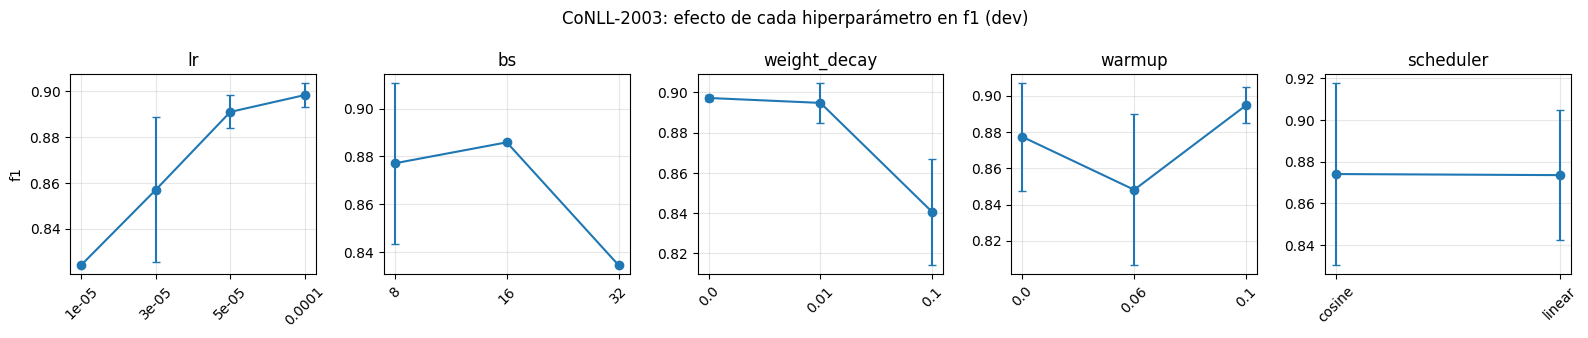

Top 5 configuraciones (media sobre las semillas disponibles):


,trial,lr,bs,weight_decay,warmup,scheduler,f1,f1_std,n_semillas
0,5,0.00010,8,0.01,0.10,cosine,0.8991,0.0063,2
1,3,0.00010,8,0.00,0.00,linear,0.8976,0.0011,2
2,7,0.00005,8,0.00,0.06,linear,0.8961,0.0000,1
3,0,0.00005,16,0.01,0.10,linear,0.8859,0.0000,1
4,2,0.00003,8,0.10,0.00,linear,0.8794,0.0000,1


Mejor configuración: {'lr': 0.0001, 'bs': 8, 'weight_decay': 0.01, 'warmup': 0.1, 'scheduler': 'cosine'} -> f1 = 0.8991
Ojo: las dos mejores están a menos de 1 desviación entre semillas; la diferencia puede ser ruido.


In [47]:
c = CFG["ner"]
ner_hp, ner_hp_raw = run_hp_search("ner", build_ner, subsample(ner_enc["train"], c["search_train"]), subsample(ner_enc["validation"], c["search_eval"]),
                                   SPACE["ner"], DEFAULTS["ner"], c["n_trials"], c["search_epochs"], "f1", c["confirm_top"])
display(ner_hp)
plot_hp_effects(ner_hp_raw, SPACE["ner"], "f1", "CoNLL-2003")
ner_best_hp, ner_best_trial = pick_best_hp(ner_hp, SPACE["ner"], "f1")

### 2.5 Entrenamiento final (mejor configuración) y evaluación en prueba

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForTokenClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.071473,0.067473,0.882776,0.909963,0.896163,0.982614
2,0.032536,0.063757,0.920007,0.923258,0.921630,0.986624
3,0.016917,0.053258,0.932039,0.937058,0.934542,0.988824
4,0.004861,0.055959,0.934147,0.940592,0.937358,0.989253


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

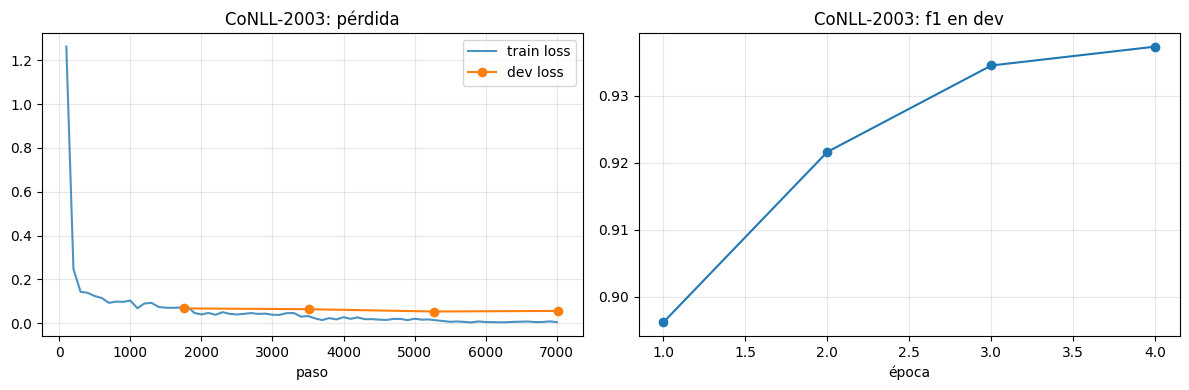

[transformers] early stopping required metric_for_best_model, but did not find eval_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.004861,0.055959,4,0.934147,0.940592,0.937358,0.989253


[transformers] early stopping required metric_for_best_model, but did not find eval_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.004861,0.149549,4,0.885873,0.901558,0.893647,0.979304


{'test_loss': 0.1495494544506073, 'test_precision': 0.8858733472512178, 'test_recall': 0.9015580736543909, 'test_f1': 0.8936468936468935, 'test_accuracy': 0.9793044040055993}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [48]:
c = CFG["ner"]
set_seed(SEED)
ner_dir = f"{OUT}/ner_final_{hp_tag(ner_best_trial, ner_best_hp)}"
ner_trainer = build_ner(ner_best_hp, subsample(ner_enc["train"], c["max_final_train"]), ner_enc["validation"],
                        c["final_epochs"], ner_dir, final=True)
fit(ner_trainer, ner_dir)
plot_history(ner_trainer, "f1", "CoNLL-2003")
ner_dev_m = ner_trainer.evaluate(ner_enc["validation"], metric_key_prefix="dev")
ner_test_m = ner_trainer.evaluate(ner_enc["test"], metric_key_prefix="test")   # única evaluación en prueba
print(ner_test_m)
ner_trainer.save_model(f"{OUT}/ner_best")
RESULTS["ner"] = dict(tarea="Etiquetado de secuencias", dataset="CoNLL-2003", modelo=c["model"],
                      mejores_hp=ner_best_hp, metrica_principal="F1 de entidad (test)",
                      valor=round(ner_test_m["test_f1"], 4), dev=round(ner_dev_m["dev_f1"], 4),
                      baseline=round(ner_baseline, 4), baseline_nombre="memorización por palabra",
                      extra=f"P={ner_test_m['test_precision']:.4f}, R={ner_test_m['test_recall']:.4f}")

### 2.6 Análisis de errores

,precision,recall,f1,number
LOC,0.9200,0.9245,0.9222,1668.0
MISC,0.7631,0.8077,0.7848,702.0
ORG,0.8520,0.8766,0.8641,1661.0
PER,0.9426,0.9443,0.9435,1617.0


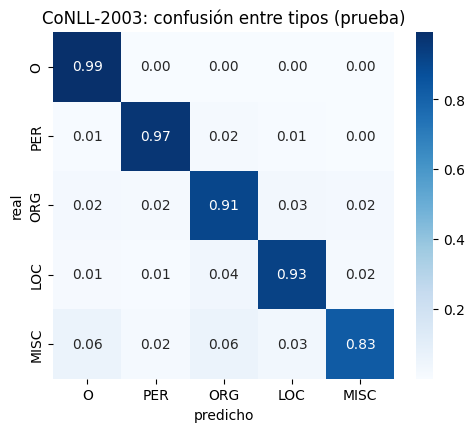

Frases con algún error: 574 de 3453

REAL : SOCCER - [JAPAN|LOC] GET LUCKY WIN , [CHINA|PER] IN SURPRISE DEFEAT .
PRED : SOCCER - [JAPAN|MISC] GET LUCKY WIN , [CHINA|LOC] IN [SURPRISE|MISC] DEFEAT .

REAL : [Japan|LOC] began the defence of their [Asian Cup|MISC] title with a lucky 2-1 win against [Syria|LOC] in a Group C championship match on Friday .
PRED : [Japan|LOC] began the defence of their [Asian Cup|MISC] title with a lucky 2-1 win against [Syria|LOC] in a [Group C|MISC] championship match on Friday .

REAL : [China|LOC] controlled most of the match and saw several chances missed until the 78th minute when [Uzbek|MISC] striker [Igor Shkvyrin|PER] took advantage of a misdirected defensive header to lob the ball over the advancing [Chinese|MISC] keeper and into an empty net .
PRED : [China|LOC] controlled most of the match and saw several chances missed until the 78th minute when [Uzbek|LOC] striker [Igor Shkvyrin|PER] took advantage of a misdirected defensive header to lob the b

In [49]:
pred = ner_trainer.predict(ner_enc["test"])
ids = np.argmax(pred.predictions, -1)
y_p = [[ner_labels[a] for a, b in zip(pr, lb) if b != -100] for pr, lb in zip(ids, pred.label_ids)]
y_t = [[ner_labels[b] for a, b in zip(pr, lb) if b != -100] for pr, lb in zip(ids, pred.label_ids)]

# 1) F1 por tipo de entidad
rep = seqeval.compute(predictions=y_p, references=y_t)
display(pd.DataFrame({k: v for k, v in rep.items() if isinstance(v, dict)}).T.round(4))

# 2) Confusión entre tipos (ignorando B-/I-), normalizada por fila
types = ["O", "PER", "ORG", "LOC", "MISC"]
strip = lambda t: t[2:] if t != "O" else "O"
flat_t = [strip(t) for s in y_t for t in s]; flat_p = [strip(t) for s in y_p for t in s]
cm = confusion_matrix(flat_t, flat_p, labels=types, normalize="true")
plt.figure(figsize=(5.5, 4.5)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=types, yticklabels=types)
plt.xlabel("predicho"); plt.ylabel("real"); plt.title("CoNLL-2003: confusión entre tipos (prueba)"); plt.show()

# 3) Frases donde el modelo se equivoca: real vs predicho
bad = [i for i in range(len(y_t)) if y_p[i] != y_t[i] and len(y_p[i]) == len(conll["test"][i]["tokens"])]
print(f"Frases con algún error: {len(bad)} de {len(y_t)}\n")
for i in bad[:6]:
    toks = conll["test"][i]["tokens"]
    print("REAL :", render_tags(toks, y_t[i])); print("PRED :", render_tags(toks, y_p[i])); print()

**Qué buscar (escribe tus conclusiones):** ¿qué tipo de entidad tiene menor F1 (suele ser `MISC`)? ¿Qué pares se confunden más en el heatmap (típicamente `ORG` ↔ `LOC`, p. ej. nombres de equipos deportivos que son nombres de ciudades)? ¿Los errores son de *tipo* (entidad bien delimitada, mal clasificada) o de *frontera*?

## 3. Secuencia a secuencia — SAMSum (resumen de diálogos)

**Dataset:** `knkarthick/samsum` (copia en formato parquet de SAMSum).

| Aspecto | Descripción |
|---|---|
| **Dominio** | Conversaciones informales de mensajería, escritas por lingüistas, con resúmenes de referencia |
| **Utilidad** | Resumir chats largos (asistentes de mensajería, atención al cliente, actas de reuniones) |
| **Entrada** | `dialogue`: conversación con turnos `Nombre: mensaje` |
| **Salida** | `summary`: resumen corto en tercera persona |
| **Tipo de problema** | Secuencia a secuencia: entrada y salida son **textos de longitud distinta** |
| **Modelo** | `t5-small` (encoder-decoder), con prefijo de tarea `summarize: ` |
| **Métrica** | ROUGE-1 / ROUGE-2 / ROUGE-L (y ROUGE-Lsum) |

Durante el entrenamiento el decoder usa **teacher forcing** (recibe la palabra correcta anterior); en la evaluación genera con **beam search**, como se vio en las diapositivas de Seq2Seq. Además de los hiperparámetros de entrenamiento, aquí también se buscan los de **generación** (número de haces, penalización de longitud, repetición de n-gramas), que no requieren reentrenar.

In [50]:
samsum = load_dataset("knkarthick/samsum")
# eliminar posibles filas vacías
samsum = samsum.filter(lambda x: bool(x["dialogue"]) and bool(x["summary"]))
print(samsum)
display(split_overview(samsum))

README.md:   0%|          | 0.00/4.36k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/9.26M [00:00<?, ?B/s]

validation.csv:   0%|          | 0.00/504k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/522k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/14731 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/818 [00:00<?, ? examples/s]

... (2 outputs left out)

Filter:   0%|          | 0/818 [00:00<?, ? examples/s]

Filter:   0%|          | 0/819 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 14731
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 818
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 819
    })
})


,partición,ejemplos,columnas
0,train,14731,"id, dialogue, summary"
1,validation,818,"id, dialogue, summary"
2,test,819,"id, dialogue, summary"


### 3.1 Análisis exploratorio

DIÁLOGO:
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

RESUMEN: Amanda baked cookies and will bring Jerry some tomorrow.
DIÁLOGO:
Sarah: I found a song on youtube and I think you'll like it
James: What song?
Sarah: <file_other>
James: Oh. I know it! 
James: I heard it before in some compilation
Sarah: I can't stop playing it over and over
James: That's exactly how I know lyrics to all of the songs on my playlist :D
Sarah: Haha. No lyrics here though. Instrumental ;D
James: Instrumental songs are different kind of music. 
James: But you have to remember that the activity you do when you listen to this song
James: Is the actvity your brain will connect to the song
James: And everytime you play this song at home
James: You'll be thinking of your work
Sarah: Yeah, I know that. That's why we sometimes say - I used to like that song, but now it just reminds me of bad memories
James: Yup. Everytime you change your partner, you have to get rid of

split                    test    train  validation
palabras_dialogo count  819.0  14731.0       818.0
                 mean    95.5     93.8        91.6
                 std     75.2     74.0        74.5
                 min      9.0      7.0        10.0
                 25%     42.0     39.0        38.0
                 50%     74.0     73.0        70.0
                 75%    126.0    128.0       127.0
                 max    516.0    803.0       540.0
palabras_resumen count  819.0  14731.0       818.0
                 mean    20.0     20.3        20.3
                 std     10.7     11.2        11.2
                 min      3.0      1.0         3.0
                 25%     12.0     12.0        12.0
                 50%     18.0     18.0        18.0
                 75%     26.0     27.0        26.0
                 max     58.0     64.0        59.0

Razón media diálogo/resumen: 4.9


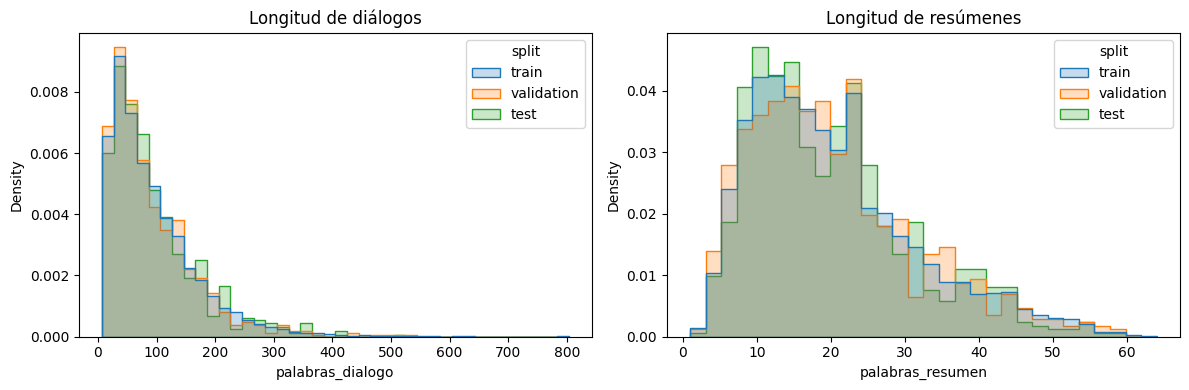

In [51]:
for i in [0, 7]:
    ex = samsum["train"][i]
    print("DIÁLOGO:\n" + ex["dialogue"]); print("\nRESUMEN:", ex["summary"]); print("=" * 70)

rows = [{"split": s, "palabras_dialogo": len(d.split()), "palabras_resumen": len(r.split())}
        for s in samsum for d, r in zip(samsum[s]["dialogue"], samsum[s]["summary"])]
sam_len = pd.DataFrame(rows)
display(sam_len.groupby("split")[["palabras_dialogo", "palabras_resumen"]].describe().round(1).T)
sam_len["razon"] = sam_len["palabras_dialogo"] / sam_len["palabras_resumen"].clip(lower=1)
print("Razón media diálogo/resumen:", round(sam_len["razon"].mean(), 1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=sam_len, x="palabras_dialogo", hue="split", bins=40, element="step", stat="density", common_norm=False, ax=ax[0]); ax[0].set_title("Longitud de diálogos")
sns.histplot(data=sam_len, x="palabras_resumen", hue="split", bins=30, element="step", stat="density", common_norm=False, ax=ax[1]); ax[1].set_title("Longitud de resúmenes")
plt.tight_layout(); plt.show()

#### a) Estructura de los diálogos y de los resúmenes
Más allá de la longitud, interesa saber **cuántos turnos y cuántos hablantes** tiene cada diálogo, y cómo se relaciona la longitud del diálogo con la del resumen.

split                test  train  validation
turnos      mean     11.2   11.2        10.8
            median   10.0   10.0         9.0
            max      30.0   46.0        30.0
hablantes   mean      2.4    2.4         2.4
            median    2.0    2.0         2.0
            max      11.0   14.0        12.0
pal_dialogo mean     95.5   93.8        91.6
            median   74.0   73.0        70.0
            max     516.0  803.0       540.0
pal_resumen mean     20.0   20.3        20.3
            median   18.0   18.0        18.0
            max      58.0   64.0        59.0
razon       mean      5.0    4.8         4.8
            median    4.0    3.9         3.8
            max      30.4   65.0        51.1

Correlación entre longitud del diálogo y del resumen (train): 0.61


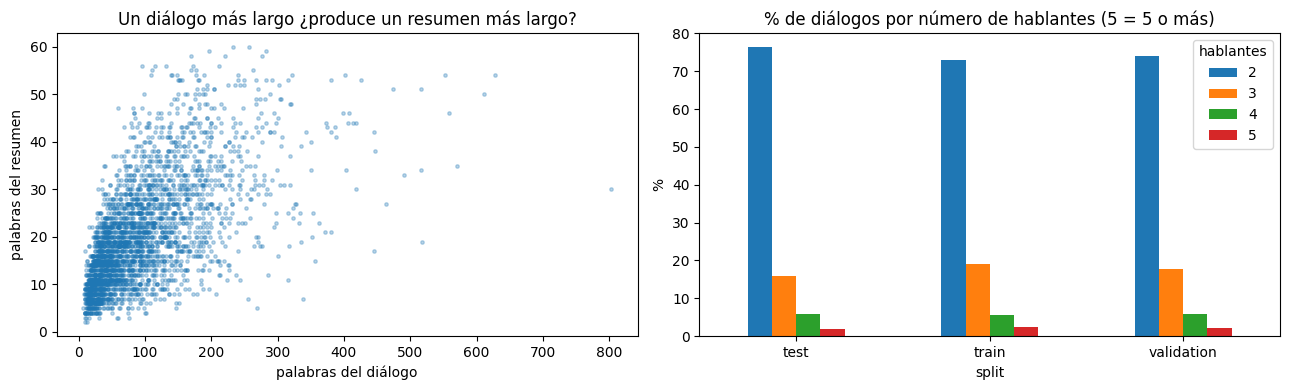

In [52]:
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
tokz = lambda s: re.findall(r"[a-z0-9']+", s.lower())

filas = []
for s in samsum:
    for dlg, res in zip(samsum[s]["dialogue"], samsum[s]["summary"]):
        lineas = [l for l in dlg.split("\n") if l.strip()]
        hab = {l.split(":", 1)[0].strip() for l in lineas if ":" in l}
        td, tr_ = tokz(dlg), tokz(res)
        set_d, bd = set(td), set(zip(td, td[1:]))
        br = list(zip(tr_, tr_[1:]))
        nombres = {w for h in hab for w in tokz(h)}
        filas.append(dict(split=s, dialogo=dlg, resumen=res, turnos=len(lineas), hablantes=len(hab),
                          pal_dialogo=len(dlg.split()), pal_resumen=len(res.split()),
                          copia=float(np.mean([w in set_d for w in tr_])) if tr_ else np.nan,
                          bigramas_nuevos=float(np.mean([b not in bd for b in br])) if br else np.nan,
                          menciona_hablante=bool(nombres & set(tr_)), marcador=bool(re.search(r"<[a-z_]+>", dlg)),
                          nombres=nombres, tokens_res=tr_))
sam_df = pd.DataFrame(filas)
sam_df["razon"] = sam_df["pal_dialogo"] / sam_df["pal_resumen"].clip(lower=1)

display(sam_df.groupby("split")[["turnos", "hablantes", "pal_dialogo", "pal_resumen", "razon"]].agg(["mean", "median", "max"]).round(1).T)
corr = sam_df[sam_df.split == "train"][["pal_dialogo", "pal_resumen"]].corr().iloc[0, 1]
print(f"Correlación entre longitud del diálogo y del resumen (train): {corr:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
m = sam_df[sam_df.split == "train"]; m = m.sample(min(3000, len(m)), random_state=SEED)
ax[0].scatter(m["pal_dialogo"], m["pal_resumen"], s=6, alpha=.3); ax[0].set_xlabel("palabras del diálogo"); ax[0].set_ylabel("palabras del resumen")
ax[0].set_title("Un diálogo más largo ¿produce un resumen más largo?")
(pd.crosstab(sam_df["split"], sam_df["hablantes"].clip(upper=5), normalize="index") * 100).plot(kind="bar", ax=ax[1], rot=0)
ax[1].set_title("% de diálogos por número de hablantes (5 = 5 o más)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

#### b) Ejemplos: un diálogo corto, uno mediano y uno largo
Se eligen, del `train`, tres diálogos con al menos 3 turnos para ver **cómo cambia el resumen según la longitud**.

In [53]:
tr_s = sam_df[(sam_df.split == "train") & (sam_df.turnos >= 3)].sort_values("pal_dialogo")
for titulo, fila in [("CORTO", tr_s.iloc[0]), ("MEDIANO", tr_s.iloc[len(tr_s) // 2]), ("LARGO", tr_s.iloc[-1])]:
    print(f"======== {titulo}: {fila.pal_dialogo} palabras, {fila.turnos} turnos, {fila.hablantes} hablantes ========")
    print(fila.dialogo[:900] + (" [...]" if len(fila.dialogo) > 900 else ""))
    print(f"\nRESUMEN ({fila.pal_resumen} palabras): {fila.resumen}\n")

======== CORTO: 7 palabras, 3 turnos, 2 hablantes ========
Bella: pizza?
Bella: or pasta?
Mick: pizza

RESUMEN (6 palabras): Bella and Mick will have pizza.

======== MEDIANO: 73 palabras, 12 turnos, 2 hablantes ========
Anna: Hi
Al: Hi...
Anna: We may have a problem
Al: You mean Chuck?
Anna: Yes... I thinks he knows about us
Al: I suspected that
Anna: A couple of years ago I told him I couldn't be his girlfriend because I was still married
Al: And then you got your divorce...
Anna: And I met you <3
Al: Poor Chuck
Anna: Who cares about him
Al: Oh come on... I feel guilty

RESUMEN (15 palabras): Anna suspects Chuck knows about her and Al. She doesn't care but Al feels guilty. 

======== LARGO: 803 palabras, 22 turnos, 2 hablantes ========
Ash: Thanks so much! I am feeling so much better. I'm gonna work on the next chapter as soon as I can. I'm hoping to actually work on it tonight, but I have to beta another story. Thanks again!!!
Mollie: Please do! I love all your stories but this one 

#### c) ¿Resumir es copiar? Extractivo frente a abstractivo

In [54]:
tr_all = sam_df[sam_df.split == "train"]
print(f"Palabras del resumen que ya estaban en el diálogo: {100 * tr_all['copia'].mean():.1f}% (media)")
print(f"Bigramas del resumen que NO están en el diálogo : {100 * tr_all['bigramas_nuevos'].mean():.1f}% (media)")
print(f"Resúmenes con ≥ 50% de bigramas nuevos          : {100 * (tr_all['bigramas_nuevos'] >= 0.5).mean():.1f}%")
print(f"Resúmenes que mencionan a algún hablante         : {100 * tr_all['menciona_hablante'].mean():.1f}%")

vocab = Counter()
for nombres, toks in zip(tr_all["nombres"], tr_all["tokens_res"]):
    vocab.update(w for w in toks if w not in nombres and w not in ENGLISH_STOP_WORDS and len(w) > 2)
print("\nPalabras más frecuentes en los resúmenes (sin nombres ni stop words):")
print(", ".join(f"{w} ({c})" for w, c in vocab.most_common(20)))

Palabras del resumen que ya estaban en el diálogo: 66.4% (media)
Bigramas del resumen que NO están en el diálogo : 77.5% (media)
Resúmenes con ≥ 50% de bigramas nuevos          : 95.7%
Resúmenes que mencionan a algún hablante         : 94.8%

Palabras más frecuentes en los resúmenes (sin nombres ni stop words):
going (1748), wants (1265), meet (1013), new (995), tomorrow (970), doesn't (781), work (732), come (730), buy (660), today (627), home (627), needs (595), got (569), party (559), time (533), it's (520), tonight (509), meeting (504), place (497), like (488)


#### d) Ruido y calidad de los datos
Los chats reales traen **marcadores de archivos** (`<file_photo>`, `<file_gif>`…), enlaces y abreviaturas. También se revisan duplicados, el solapamiento entre `train` y `test` y los resúmenes demasiado cortos.

In [55]:
marc = Counter(m for d in samsum["train"]["dialogue"] for m in re.findall(r"<[a-z_]+>", d))
print(f"Diálogos del train con marcadores de archivo: {100 * tr_all['marcador'].mean():.1f}% | marcadores más comunes: {dict(marc.most_common(5))}")
url = np.mean([bool(re.search(r"https?://|www\.", d)) for d in samsum["train"]["dialogue"]]) * 100
print(f"Diálogos con enlaces web: {url:.1f}%")

dup = int(tr_all["dialogo"].duplicated().sum())
solap = len(set(tr_all["dialogo"]) & set(sam_df[sam_df.split == "test"]["dialogo"]))
cortos = int((tr_all["pal_resumen"] <= 3).sum())
print(f"Diálogos repetidos en train: {dup} | diálogos que están a la vez en train y test: {solap} | resúmenes de ≤ 3 palabras: {cortos}")

if marc:
    ej = tr_all[tr_all.marcador].iloc[0]
    print("\nEjemplo con marcador de archivo:\n" + ej.dialogo[:400] + "\n→ " + ej.resumen)

Diálogos del train con marcadores de archivo: 17.8% | marcadores más comunes: {'<file_photo>': 1738, '<file_gif>': 864, '<file_other>': 805, '<file_video>': 215, '<file_picture>': 62}
Diálogos con enlaces web: 0.1%
Diálogos repetidos en train: 476 | diálogos que están a la vez en train y test: 42 | resúmenes de ≤ 3 palabras: 41

Ejemplo con marcador de archivo:
Sarah: I found a song on youtube and I think you'll like it
James: What song?
Sarah: <file_other>
James: Oh. I know it! 
James: I heard it before in some compilation
Sarah: I can't stop playing it over and over
James: That's exactly how I know lyrics to all of the songs on my playlist :D
Sarah: Haha. No lyrics here though. Instrumental ;D
James: Instrumental songs are different kind of music. 
Jam
→ Sarah sends James an instrumental song he might like. James knows the song. The brain connects the songs to the context they were played in and brings to mind the associated memories.


#### e) Qué aprendemos y cómo afecta al modelado

| Hallazgo (confírmalo con tus cifras) | Decisión que justifica |
|---|---|
| El diálogo es varias veces más largo que su resumen | La tarea es de **compresión**: se necesita un modelo generativo (encoder-decoder), no solo clasificación |
| Muchas palabras del resumen están en el diálogo, pero una parte importante de los bigramas es nueva | Es **abstractivo con mucha reutilización de vocabulario**: un baseline extractivo (*Lead-3*) puntúa algo, pero el modelo entrenado debe superarlo |
| La mayoría de los resúmenes menciona a los hablantes y narra en tercera persona | El modelo debe aprender el **estilo** del resumen (quién dice qué), no solo recortar frases |
| Los resúmenes son cortos y su longitud crece poco con la del diálogo | `max_target = 64` basta; el modelo no debe generar de más (se busca la `length_penalty` en 3.6) |
| Hay diálogos largos y marcadores de archivo | `max_input = 512` cubre casi todo (se mide en 3.2); los marcadores se dejan tal cual, ya que aparecen también en los resúmenes de referencia |
| Sin solapamiento train/test (si lo confirma la salida) | La evaluación en test es limpia |
| ROUGE mide solapamiento de n-gramas, no significado | Además de ROUGE se **leen ejemplos** generados (3.7) |

### 3.2 Tokenización

In [56]:
t5_tok = AutoTokenizer.from_pretrained(CFG["sum"]["model"])
MAX_IN, MAX_OUT = CFG["sum"]["max_input"], CFG["sum"]["max_target"]
# T5 necesita el prefijo de tarea; BART no. Y la familia T5 es inestable en fp16 (BART sí lo tolera).
IS_T5 = "t5" in CFG["sum"]["model"].lower()
PREFIX = "summarize: " if IS_T5 else ""
USE_FP16_SUM = HAS_GPU and not IS_T5

def prep_sum(batch):
    enc = t5_tok([PREFIX + d for d in batch["dialogue"]], max_length=MAX_IN, truncation=True)
    enc["labels"] = t5_tok(text_target=batch["summary"], max_length=MAX_OUT, truncation=True)["input_ids"]
    return enc

sum_enc = samsum.map(prep_sum, batched=True, remove_columns=samsum["train"].column_names)
print(sum_enc)

# ¿Cuántos ejemplos se truncan? (longitudes sin truncar, medidas con el tokenizador real)
_raw = samsum["train"].map(lambda b: {"li": [len(x) for x in t5_tok([PREFIX + d for d in b["dialogue"]])["input_ids"]],
                                       "lo": [len(x) for x in t5_tok(text_target=b["summary"])["input_ids"]]},
                           batched=True, remove_columns=samsum["train"].column_names)
length_report(_raw["li"], MAX_IN, "SAMSum train, entrada (tokens)")
length_report(_raw["lo"], MAX_OUT, "SAMSum train, resumen (tokens)")

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

Map:   0%|          | 0/14731 [00:00<?, ? examples/s]

Map:   0%|          | 0/818 [00:00<?, ? examples/s]

Map:   0%|          | 0/819 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 14731
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 818
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 819
    })
})


Map:   0%|          | 0/14731 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (569 > 512). Running this sequence through the model will result in indexing errors


SAMSum train, entrada (tokens): mediana=121 | p95=369 | p99=527 | máx=1155 | truncados con max_len=512: 1.14%
SAMSum train, resumen (tokens): mediana=25 | p95=59 | p99=73 | máx=94 | truncados con max_len=64: 3.22%


### 3.3 Modelo, métricas, generación y baselines

In [57]:
rouge = evaluate.load("rouge")

def sent_fmt(s):
    # ROUGE-Lsum espera una oración por línea; ROUGE-1/2/L no cambian con esto
    return "\n".join(s.strip().split(". "))

def rouge_dict(preds, refs):
    r = rouge.compute(predictions=[sent_fmt(p) for p in preds], references=[sent_fmt(x) for x in refs], use_stemmer=True)
    return {k: round(v * 100, 2) for k, v in r.items()}

def metrics_sum(ep):
    preds, labels = ep
    if isinstance(preds, tuple): preds = preds[0]
    # el Trainer rellena con -100 las secuencias generadas de distinta longitud: hay que reemplazarlo para poder decodificar
    preds = np.where(preds != -100, preds, t5_tok.pad_token_id)
    labels = np.where(labels != -100, labels, t5_tok.pad_token_id)
    out = rouge_dict(t5_tok.batch_decode(preds, skip_special_tokens=True), t5_tok.batch_decode(labels, skip_special_tokens=True))
    out["gen_len"] = float(np.mean([np.count_nonzero(p != t5_tok.pad_token_id) for p in preds]))
    return out

def build_sum(hp, train_ds, eval_ds, epochs, out, final, seed=SEED):
    model = AutoModelForSeq2SeqLM.from_pretrained(CFG["sum"]["model"])
    # generation_max_length es imprescindible: sin él, la evaluación genera con el máximo por defecto (~20 tokens) y corta los resúmenes
    args = make_args(Seq2SeqTrainingArguments, out, hp, epochs, final, "eval_rougeL", USE_FP16_SUM, seed=seed,
                     predict_with_generate=True, generation_max_length=MAX_OUT)
    return Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                          data_collator=DataCollatorForSeq2Seq(t5_tok, model=model),
                          compute_metrics=metrics_sum, callbacks=callbacks_for(final, epochs), **{TOK_KW: t5_tok})

def generate_summaries(model, dialogues, bs=32, **gen_kw):
    # genera resúmenes por lotes; gen_kw = num_beams, length_penalty, no_repeat_ngram_size, ...
    model.eval(); outs = []
    for i in range(0, len(dialogues), bs):
        b = t5_tok([PREFIX + d for d in dialogues[i:i + bs]], return_tensors="pt", padding=True,
                   truncation=True, max_length=MAX_IN).to(model.device)
        with torch.no_grad():
            out = model.generate(**b, max_new_tokens=MAX_OUT, **gen_kw)
        outs += t5_tok.batch_decode(out, skip_special_tokens=True)
    return outs

test_dlg, test_ref = samsum["test"]["dialogue"], samsum["test"]["summary"]

# Baseline 1 (extractivo): los 3 primeros turnos del diálogo ("Lead-3")
lead3 = rouge_dict(["\n".join(d.split("\n")[:3]) for d in test_dlg], test_ref)
print("Baseline Lead-3 (prueba):", lead3)

# Baseline 2: el mismo modelo SIN fine-tuning (zero-shot con el prefijo de tarea)
_m0 = AutoModelForSeq2SeqLM.from_pretrained(CFG["sum"]["model"]).to(DEVICE)
zs = rouge_dict(generate_summaries(_m0, test_dlg, num_beams=4, early_stopping=True), test_ref)
print("Modelo sin fine-tuning (prueba):", zs)
del _m0; free_memory()

Baseline Lead-3 (prueba): {'rouge1': np.float64(31.26), 'rouge2': np.float64(8.66), 'rougeL': np.float64(24.15), 'rougeLsum': np.float64(29.51)}


model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Modelo sin fine-tuning (prueba): {'rouge1': np.float64(27.1), 'rouge2': np.float64(7.22), 'rougeL': np.float64(21.37), 'rougeLsum': np.float64(23.72)}


### 3.4 Búsqueda de hiperparámetros de entrenamiento (muestra pequeña)
La métrica se calcula generando resúmenes del *dev* (500 ejemplos: con 200 la estimación era demasiado ruidosa). En esta etapa se genera de forma voraz (sin beam search) para que cada prueba sea rápida; los parámetros de generación se afinan después, en 3.6.

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Step,Training Loss
100,2.308298
200,2.068295
300,1.893501
400,1.884045
500,1.778349


Training Loss,Validation Loss,Step,Rouge1,Rouge2,Rougel,Rougelsum,Gen Len
1.778349,1.803522,564,44.530000,20.220000,36.550000,41.200000,24.134000


{'trial': 0, 'lr': 0.0003, 'bs': 16, 'weight_decay': 0.01, 'warmup': 0.1, 'scheduler': 'linear', 'label_smoothing': 0.0, 'seed': 42, 'train_loss': 1.9592, 'minutos': 4.7425, 'loss': 1.8035, 'rouge1': 44.53, 'rouge2': 20.22, 'rougeL': 36.55, 'rougeLsum': 41.2, 'gen_len': 24.134}


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Step,Training Loss
100,2.509453
200,2.146973
300,2.154993
400,2.053953
500,1.972001
600,1.981544
700,2.008067
800,1.955934
900,1.897072
1000,1.923834


... (23 outputs left out)

Step,Training Loss
100,3.519081
200,3.154756


Training Loss,Validation Loss,Step,Rouge1,Rouge2,Rougel,Rougelsum,Gen Len
3.154756,3.154946,282,45.690000,21.060000,37.330000,41.950000,24.250000


{'trial': 5, 'lr': 0.001, 'bs': 32, 'weight_decay': 0.01, 'warmup': 0.0, 'scheduler': 'linear', 'label_smoothing': 0.1, 'seed': 7, 'train_loss': 3.2474, 'minutos': 5.1297, 'loss': 3.1549, 'rouge1': 45.69, 'rouge2': 21.06, 'rougeL': 37.33, 'rougeLsum': 41.95, 'gen_len': 24.25}


,trial,lr,bs,weight_decay,warmup,scheduler,label_smoothing,loss,rouge1,rouge2,rougeL,rougeLsum,gen_len,train_loss,minutos,rougeL_std,n_semillas
0,5,0.0010,32,0.01,0.00,linear,0.1,3.1596,45.635,21.015,37.275,41.915,24.341,3.2467,10.2649,0.055,2
1,2,0.0003,32,0.00,0.10,linear,0.1,3.2136,44.395,20.770,36.875,41.205,23.083,3.4525,10.2717,0.365,2
2,0,0.0003,16,0.01,0.10,linear,0.0,1.8035,44.530,20.220,36.550,41.200,24.134,1.9592,4.7425,0.000,1
3,3,0.0001,8,0.00,0.00,linear,0.0,1.8462,43.480,20.070,35.960,40.230,22.378,2.0190,4.4394,0.000,1
4,4,0.0003,32,0.10,0.10,cosine,0.0,1.8246,43.500,19.950,35.920,40.160,23.500,2.0060,5.1068,0.000,1
5,1,0.0001,8,0.10,0.06,linear,0.0,1.8451,43.430,19.840,35.860,40.130,22.864,2.0406,4.4483,0.000,1


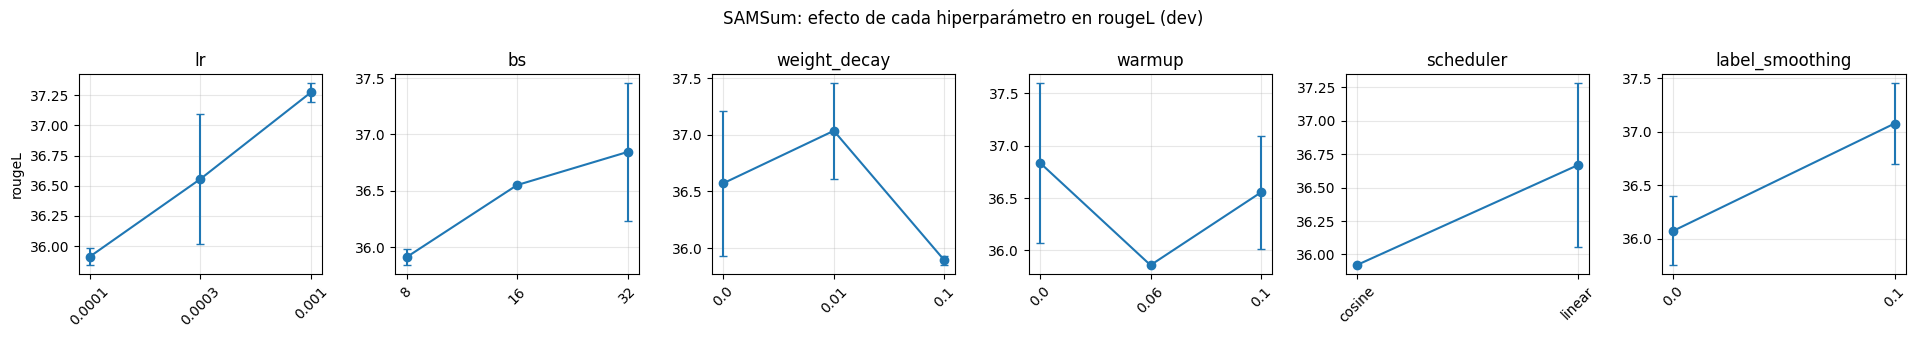

Top 5 configuraciones (media sobre las semillas disponibles):


,trial,lr,bs,weight_decay,warmup,scheduler,label_smoothing,rougeL,rougeL_std,n_semillas
0,5,0.0010,32,0.01,0.0,linear,0.1,37.275,0.055,2
1,2,0.0003,32,0.00,0.1,linear,0.1,36.875,0.365,2
2,0,0.0003,16,0.01,0.1,linear,0.0,36.550,0.000,1
3,3,0.0001,8,0.00,0.0,linear,0.0,35.960,0.000,1
4,4,0.0003,32,0.10,0.1,cosine,0.0,35.920,0.000,1


Mejor configuración: {'lr': 0.001, 'bs': 32, 'weight_decay': 0.01, 'warmup': 0.0, 'scheduler': 'linear', 'label_smoothing': 0.1} -> rougeL = 37.275


In [58]:
c = CFG["sum"]
sum_hp, sum_hp_raw = run_hp_search("sum", build_sum, subsample(sum_enc["train"], c["search_train"]), subsample(sum_enc["validation"], c["search_eval"]),
                                   SPACE["sum"], DEFAULTS["sum"], c["n_trials"], c["search_epochs"], "rougeL", c["confirm_top"])
display(sum_hp)
plot_hp_effects(sum_hp_raw, SPACE["sum"], "rougeL", "SAMSum")
sum_best_hp, sum_best_trial = pick_best_hp(sum_hp, SPACE["sum"], "rougeL")

### 3.5 Entrenamiento final (mejor configuración)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


Reanudando desde outputs/sum_final_t5_8b9ee0/checkpoint-2766


[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


Epoch,Training Loss,Validation Loss


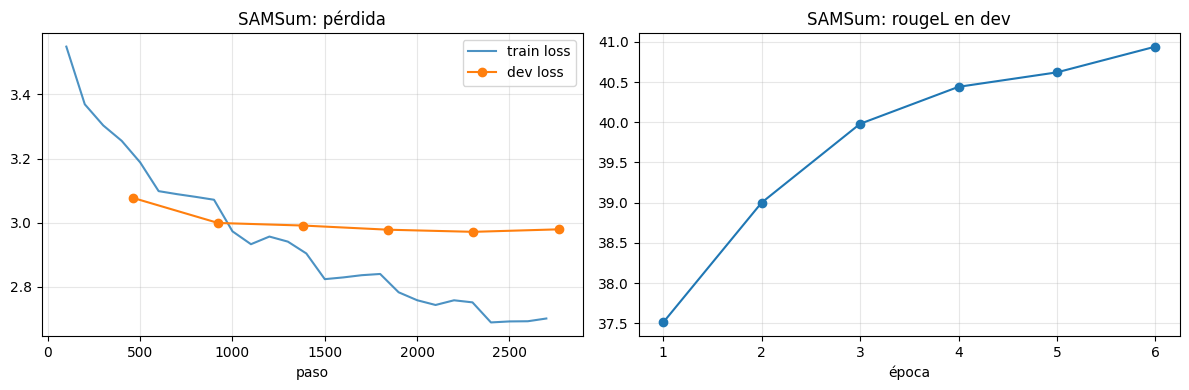

In [65]:
c = CFG["sum"]
set_seed(SEED)
sum_dir = f"{OUT}/sum_final_{hp_tag(sum_best_trial, sum_best_hp)}"
sum_trainer = build_sum(sum_best_hp, subsample(sum_enc["train"], c["max_final_train"]), sum_enc["validation"],
                        c["final_epochs"], sum_dir, final=True)
fit(sum_trainer, sum_dir)
plot_history(sum_trainer, "rougeL", "SAMSum")

### 3.6 Búsqueda de parámetros de generación y evaluación en prueba
Con el modelo ya entrenado se prueban, **sobre el dev**, el número de haces (`num_beams`) y la penalización de longitud (`length_penalty`); luego se comprueba si bloquear la repetición de trigramas (`no_repeat_ngram_size=3`) ayuda. Se elige la mejor por ROUGE-L y solo entonces se evalúa **una vez** en prueba. La configuración elegida se guarda dentro del modelo (`generation_config`).

In [60]:
m_best = sum_trainer.model.eval()
dev_sub = subsample(samsum["validation"], CFG["sum"]["search_eval"])

grid = [dict(num_beams=1)] + [dict(num_beams=b, length_penalty=lp, early_stopping=True) for b in (4, 6) for lp in (0.8, 1.0, 1.5)]

def gen_row(kw):
    g = generate_summaries(m_best, dev_sub["dialogue"], **kw)
    return {"_kw": kw, **{k: v for k, v in kw.items() if k != "early_stopping"},
            **rouge_dict(g, dev_sub["summary"]), "palabras_gen": round(float(np.mean([len(x.split()) for x in g])), 1)}

gen_rows = [gen_row(kw) for kw in grid]
best_row = max(gen_rows, key=lambda r: r["rougeL"])
r3 = gen_row({**best_row["_kw"], "no_repeat_ngram_size": 3})          # ¿ayuda bloquear repeticiones?
gen_rows.append(r3)
if r3["rougeL"] > best_row["rougeL"]: best_row = r3
best_kw = best_row["_kw"]

display(pd.DataFrame(gen_rows).drop(columns="_kw").sort_values("rougeL", ascending=False).reset_index(drop=True))
print("Mejor configuración de generación:", best_kw)

# se guarda con el modelo para que pipelines y el Hub la usen por defecto
m_best.generation_config.update(max_new_tokens=MAX_OUT, **best_kw)

# Evaluación ÚNICA en prueba con esa configuración
test_preds = generate_summaries(m_best, test_dlg, **best_kw)
sum_test_m = rouge_dict(test_preds, test_ref)
sum_dev_m = {k: best_row[k] for k in ("rouge1", "rouge2", "rougeL", "rougeLsum")}
print("Prueba:", sum_test_m)
sum_trainer.save_model(f"{OUT}/sum_best")

RESULTS["sum"] = dict(tarea="Secuencia a secuencia", dataset="SAMSum", modelo=CFG["sum"]["model"],
                      mejores_hp={**sum_best_hp, "generación": {k: v for k, v in best_kw.items() if k != "early_stopping"}},
                      metrica_principal="ROUGE-L (test)",
                      valor=sum_test_m["rougeL"], dev=sum_dev_m["rougeL"],
                      baseline=lead3["rougeL"], baseline_nombre=f"Lead-3 (sin fine-tuning: {zs['rougeL']:.2f})",
                      extra=f"R1={sum_test_m['rouge1']:.2f}, R2={sum_test_m['rouge2']:.2f}, Lsum={sum_test_m['rougeLsum']:.2f}")

[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

,num_beams,rouge1,rouge2,rougeL,rougeLsum,palabras_gen,length_penalty,no_repeat_ngram_size
0,6,50.66,27.25,42.75,46.78,16.5,0.8,NaN
1,6,51.70,27.24,42.67,47.71,19.4,1.5,NaN
2,4,50.78,27.30,42.58,46.79,16.9,0.8,NaN
3,6,50.53,27.04,42.56,46.66,16.5,0.8,3.0
4,6,51.16,27.29,42.50,47.06,17.7,1.0,NaN
5,4,50.90,27.09,42.27,46.83,18.0,1.0,NaN
6,4,51.01,26.93,42.07,47.08,19.4,1.5,NaN
7,1,49.60,25.68,41.35,45.87,17.8,NaN,NaN


[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Mejor configuración de generación: {'num_beams': 6, 'length_penalty': 0.8, 'early_stopping': True}


[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

Prueba: {'rouge1': np.float64(48.98), 'rouge2': np.float64(24.41), 'rougeL': np.float64(40.79), 'rougeLsum': np.float64(44.85)}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 4. Mejores modelos encontrados


,tarea,dataset,modelo,mejores_hp,metrica_principal,valor,dev,baseline,baseline_nombre,extra
0,Clasificación de secuencias,GLUE/SST-2,distilbert-base-uncased,"{'lr': 3e-05, 'bs': 32, 'weight_decay': 0.01, 'warmup': 0.1, 'scheduler': 'linear', 'label_smoothing': 0.0}",accuracy (test),0.9243,0.8968,0.5092,clase mayoritaria,F1=0.9234
1,Etiquetado de secuencias,CoNLL-2003,distilbert-base-cased,"{'lr': 0.0001, 'bs': 8, 'weight_decay': 0.01, 'warmup': 0.1, 'scheduler': 'cosine'}",F1 de entidad (test),0.8936,0.9374,0.5488,memorización por palabra,"P=0.8859, R=0.9016"
2,Secuencia a secuencia,SAMSum,t5-small,"{'lr': 0.001, 'bs': 32, 'weight_decay': 0.01, 'warmup': 0.0, 'scheduler': 'linear', 'label_smoothing': 0.1, 'generación': {'num_beams': 6, 'length_penalty': 0.8}}",ROUGE-L (test),40.7900,42.7500,24.1500,Lead-3 (sin fine-tuning: 21.37),"R1=48.98, R2=24.41, Lsum=44.85"


,trial,lr,bs,weight_decay,warmup,scheduler,label_smoothing,loss,accuracy,f1,...,tarea,precision,recall,f1_std,rouge1,rouge2,rougeL,rougeLsum,gen_len,rougeL_std
0,0,0.00003,32,0.01,0.10,linear,0.0,0.3500,0.8544,0.8612,...,SST-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0.00001,16,0.10,0.06,linear,0.0,0.3638,0.8532,0.8581,...,SST-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,0.00001,16,0.00,0.00,linear,0.0,0.3701,0.8532,0.8578,...,SST-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2,0.00002,64,0.00,0.10,linear,0.1,0.4478,0.8486,0.8559,...,SST-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,6,0.00003,32,0.00,0.00,cosine,0.0,0.3803,0.8486,0.8565,...,SST-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,7,0.00001,32,0.00,0.06,cosine,0.1,0.4430,0.8417,0.8456,...,SST-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,4,0.00010,16,0.10,0.10,cosine,0.0,0.5289,0.8394,0.8465,...,SST-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,5,0.00005,64,0.01,0.00,linear,0.1,0.4312,0.8349,0.8487,...,SST-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,5,0.00010,8,0.01,0.10,cosine,NaN,0.0645,0.9823,0.8991,...,CoNLL-2003,0.8969,0.9013,0.0063,NaN,NaN,NaN,NaN,NaN,NaN
1,3,0.00010,8,0.00,0.00,linear,NaN,0.0636,0.9827,0.8976,...,CoNLL-2003,0.8948,0.9005,0.0011,NaN,NaN,NaN,NaN,NaN,NaN


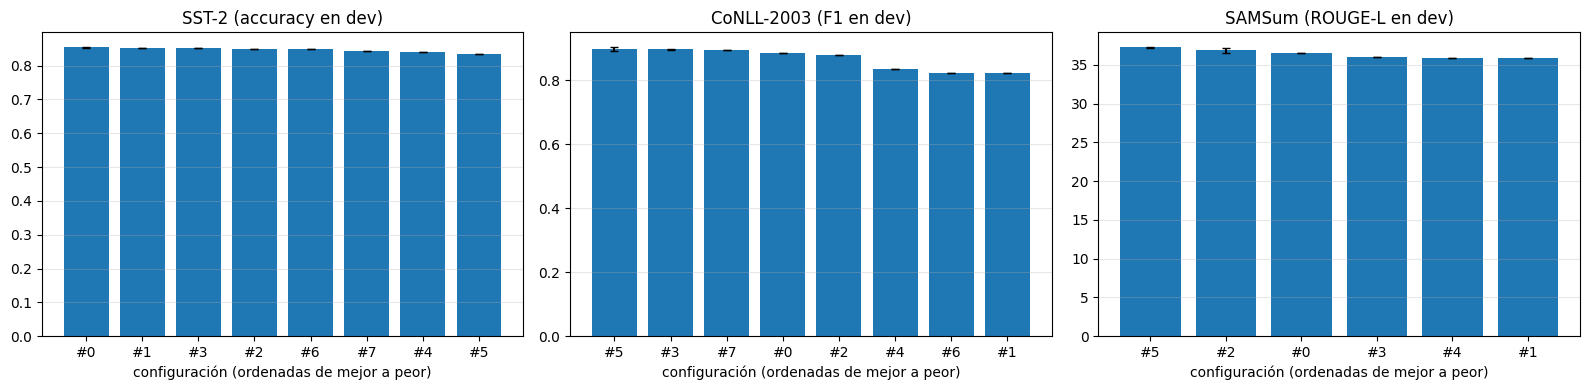

In [62]:
final_df = pd.DataFrame(RESULTS.values())
pd.set_option("display.max_colwidth", None)
display(final_df)

# Resumen de todas las búsquedas de hiperparámetros
hp_all = pd.concat([sst_hp.assign(tarea="SST-2"), ner_hp.assign(tarea="CoNLL-2003"), sum_hp.assign(tarea="SAMSum")])
display(hp_all)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (df, m, t) in zip(ax, [(sst_hp, "accuracy", "SST-2 (accuracy en dev)"), (ner_hp, "f1", "CoNLL-2003 (F1 en dev)"), (sum_hp, "rougeL", "SAMSum (ROUGE-L en dev)")]):
    plot_trials(df, m, t, a)
plt.tight_layout(); plt.show()

with open(f"{OUT}/resultados.json", "w") as f:
    json.dump({"final": RESULTS, "busqueda_hp": json.loads(hp_all.to_json(orient="records"))}, f, indent=2, ensure_ascii=False, default=str)
final_df.to_csv(f"{OUT}/resumen_final.csv", index=False)

## 5. Inferencia de demostración y publicación

In [63]:
dev_idx = 0 if HAS_GPU else -1

clf = pipeline("text-classification", model=f"{OUT}/sst2_best", device=dev_idx)
print(clf(["A touching and beautifully acted film.", "The plot was a mess and I was bored the whole time."]))

ner = pipeline("token-classification", model=f"{OUT}/ner_best", aggregation_strategy="simple", device=dev_idx)
for e in ner("Barack Obama visited Microsoft headquarters in Seattle last Tuesday."):
    print(e["word"], "->", e["entity_group"], round(float(e["score"]), 3))

dialogue = ("Ana: Are we still on for dinner tonight?\nLuis: Yes! Can we make it 8pm instead of 7?\n"
            "Ana: Sure, I'll book a table at the Italian place.\nLuis: Perfect, see you there.")
m = AutoModelForSeq2SeqLM.from_pretrained(f"{OUT}/sum_best").to(DEVICE)       # trae guardada la mejor configuración de generación
ids = t5_tok(PREFIX + dialogue, return_tensors="pt").to(DEVICE)
print(t5_tok.decode(m.generate(**ids)[0], skip_special_tokens=True))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9979052543640137}, {'label': 'NEGATIVE', 'score': 0.9966316819190979}]


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Barack Obama -> PER 0.998
Microsoft -> ORG 0.999
Seattle -> LOC 1.0


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Ana will book a table at the Italian place at 8 pm tonight.
